In [ ]:
# ==============================================================================
# Purpose:
#   DC-focused CNA + gene-program interpretation:
#     (1) run CNA neighborhood association for race (NHB vs NHW) in DC cells
#         within each DC subtype (cDC1/cDC2/pDC) x disease state,
#     (2) correlate per-cell race_coef with gene expression (fast Spearman),
#     (3) run preranked GSEA on rho,
#     (4) make Figure 6_2 panels: DC UMAPs (celltype, race, race_coef) and
#         pathway NES bar panels + per-state bubble plots for selected ImmPort sets.
#
# Steps:
#   1) Set plotting params; load palettes + metadata; map covariates into dat.obs.
#   2) Subset DC; load saved UMAP coords; compute neighbors.
#   3) Build sample-level table (samplem) with covariates; add batch (Pool137/Pool138).
#   4) Run cna.tl.association for race (return_full=True); save DC CNA object + full res.
#   5) Create disease_state labels; for each (DC subtype x disease_state):
#        - run CNA race association (allow_low_sample_size=True); compute Spearman(gene, race_coef);
#          prerank GSEA; save CSVs. Repeat per disease_state for all DC cells.
#   6) Load overall_DC CNA; plot UMAPs: celltype_level3, race, and race_coef (sig-only).
#   7) Aggregate GSEA CSVs into one table; plot selected pathway NES bar panels;
#      generate bubble plots per disease_state (NES vs term; size=Tag%).
# ==============================================================================

# Header

In [1]:
from utils import *

In [2]:
import sys
sys.path.insert(0, '/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src')
import cna

In [3]:
import gseapy as gp
import scanpy as sc
from itertools import product
from matplotlib.patches import Patch
from textwrap import fill

In [4]:
os.chdir('../')

In [5]:
import scanpy as sc
sc.settings.set_figure_params(dpi=600, dpi_save=600)  # 600 dpi for publication
sc.settings.figdir = "plots/Figure1"

rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none',    # Keep SVG text as font
    'font.size': 6,            # Main font size (5–7pt recommended)
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    'figure.dpi': 600,

    # --- Nature Immunology-style axes/ticks ---
    'axes.linewidth': 0.5,          # Axis lines: 0.5 pt
    'xtick.major.width': 0.5,        # Major tick lines
    'ytick.major.width': 0.5,
    'xtick.minor.width': 0.5,
    'ytick.minor.width': 0.5,
    'lines.linewidth': 0.7,          # Plot/data lines
    'axes.grid': False,              # No grid lines

    # --- Ticks on all sides ---
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.top': False,
    'xtick.bottom': False,
    'ytick.left': True,
    'ytick.right': False,


    # --- Tick label padding (minimal) ---
    'xtick.major.pad': 0,
    'ytick.major.pad': 0,

    # ---- Thin lines for Nature Immunology style ----
    'lines.linewidth': 0.5,     # General line width (default: 1.5)
    'patch.linewidth': 0.5,     # Outline for violin/bars (default: 1.0)
    
})

# plt.rcParams['axes.grid'] = False      # Extra guarantee, if using seaborn
# sns.set_style("white")                 # Removes upper/right axes and grid

# -- Scanpy vector-friendly mode --
sc.settings._vector_friendly = True

In [6]:
cells_group = {
    'B':['Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    'T':['Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    'DC':[
   'cDC1',
 'cDC2',
 'pDC'     
    ],
    'Mono':[
        'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    'NK':[
        'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}

In [7]:
import numpy as np
import pandas as pd
from scipy.stats import rankdata
from scipy import sparse
from scipy.stats import t as student_t
from statsmodels.stats.multitest import multipletests

def fast_spearman_ann(adata, obs_key, genes=None, chunk_size=2000, eps=1e-12):
    """
    Fast Spearman correlation between a per-cell variable (obs_key)
    and expression of each gene in adata.
    Returns a DataFrame with columns: rho, pval, fdr.
    """
    if genes is None:
        genes = adata.var_names
    X = adata[:, genes].X
    n_cells, n_genes = X.shape

    # rank-transform the covariate
    c = pd.to_numeric(adata.obs[obs_key], errors='coerce').to_numpy()
    r_c = rankdata(c, method='average')
    r_c0 = r_c - r_c.mean()
    norm_rc0 = np.linalg.norm(r_c0) + eps

    rho = np.empty(n_genes, dtype=float)

    for start in range(0, n_genes, chunk_size):
        end = min(start + chunk_size, n_genes)
        Xi = X[:, start:end]

        if sparse.issparse(Xi):
            Xi = Xi.toarray()

        # rank each gene (column) across cells
        R = np.apply_along_axis(rankdata, 0, Xi, method='average')
        R0 = R - R.mean(axis=0, keepdims=True)
        denomX = np.linalg.norm(R0, axis=0) + eps

        # Pearson on ranks = Spearman
        rho[start:end] = (R0.T @ r_c0) / (norm_rc0 * denomX)

    # --- p-values (two-sided) via t-approximation ---
    df = n_cells - 2
    # Clamp |rho| to < 1 to avoid division by zero
    rho_clamped = np.clip(rho, -1 + 1e-15, 1 - 1e-15)
    t_stat = rho_clamped * np.sqrt(df / (1 - rho_clamped**2))
    pval = 2 * student_t.sf(np.abs(t_stat), df=df)

    # --- FDR (Benjamini–Hochberg) ---
    fdr = multipletests(pval, method='fdr_bh')[1]

    out = pd.DataFrame(
        {'rho': rho, 'pval': pval, 'fdr': fdr},
        index=pd.Index(genes, name='gene')
    )
    out.name = f'spearman_{obs_key}'
    return out

In [8]:
with open('data/Legends/celltypelevel3_palette.pkl','rb') as f:
    palette_all = pkl.load(f)

palette_all

{'Naive B': (0.843137, 0.0, 0.0),
 'Mature B': (0.54902, 0.235294, 1.0),
 'Memory B': (0.007843, 0.533333, 0.0),
 'Plasmablast': (0.0, 0.67451, 0.780392),
 'Naive CD4T': (0.596078, 1.0, 0.0),
 'Central Memory CD4T': (1.0, 0.498039, 0.819608),
 'Effector Memory CD4T': (0.423529, 0.0, 0.309804),
 'Cytotoxic CD4T': (1.0, 0.647059, 0.188235),
 'Treg': (0.345098, 0.231373, 0.0),
 'Naive CD8T': (0.0, 0.341176, 0.34902),
 'Central Memory CD8T': (0.0, 0.0, 0.866667),
 'Effector Memory CD8T': (0.0, 0.992157, 0.811765),
 'Double Negative T': (0.631373, 0.458824, 0.415686),
 'γδ T': (0.737255, 0.717647, 1.0),
 'MAIT': (0.584314, 0.709804, 0.470588),
 'cDC1': (0.752941, 0.015686, 0.72549),
 'cDC2': (0.392157, 0.329412, 0.454902),
 'pDC': (0.47451, 0.0, 0.0),
 'Classical Monocyte': (0.027451, 0.454902, 0.847059),
 'Intermediate Monocyte': (0.996078, 0.960784, 0.564706),
 'Nonclassical Monocyte': (0.0, 0.294118, 0.0),
 'Cytotoxic Monocyte': (0.560784, 0.478431, 0.0),
 'CD56-dim NK': (1.0, 0.447059, 

# Load

In [10]:
meta = pd.read_csv('data/01_meta/meta_pt.csv', index_col=0)
#meta.index = [x.replace('_','-') for x in meta.index]

meta['race-stage'] = meta['race'].astype(str) + '-' + meta['group'].astype(str)
meta = meta.drop(columns = ['race_stage'])

meta['race-stage'] = pd.Categorical(
    meta['race-stage'],
    categories=['NHW-HRL', 'NHW-DCIS', 'NHW-BC','NHB-HRL', 'NHB-DCIS', 'NHB-BC'],
    ordered=True
    )

meta

,dataset_name,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
sampleid,,,,,,,,,
9-D,Pool137_7,1,95,DCIS,NHW,37.0,N,Y,NHW-DCIS
30-D,Pool137_12,1,92,DCIS,NHW,78.0,N,N,NHW-DCIS
36-D,Pool137_18,1,93,DCIS,NHB,39.0,N,Y,NHB-DCIS
119-D,Pool137_20,1,95,DCIS,NHB,80.0,N,Y,NHB-DCIS
28-D,Pool137_24,1,94,DCIS,NHW,53.0,N,N,NHW-DCIS
53-D,Pool137_27,1,96,DCIS,NHB,45.0,N,N,NHB-DCIS
77-D,Pool137_30,1,90,DCIS,NHW,45.0,N,N,NHW-DCIS
31-D,Pool138_6,2,93,DCIS,NHW,44.0,N,N,NHW-DCIS
6-H,Pool137_6,1,94,HRL,NHW,71.1,N,Y,NHW-HRL


In [11]:
dat = sc.read_h5ad(
    'data/03_cleandata/ft_all.h5ad'
)

dat.obs

,nFeaturess_RNA,nFeaturess_RNA_by_counts,total_counts,total_counts_mt,pct_counts_mt,doublets_score,nCount_RNA,nFeature_RNA,percent.mt,predicted.celltype.l1.score,...,predicted.celltype.l3,mapping.score,RNA_snn_res.0.8,seurat_clusters,dataset_name,RNA_snn_res.0.1,S.Score,G2M.Score,Phase,celltype_level3
Pool137_10_AAACCTGAGACTCGGA-1,1095.0,1095,2669.0,80.0,2.997377,0.039230,2669.0,1095.0,2.997377,0.987477,...,CD4 TCM_1,0.827455,0,0,Pool137_10,0,-0.035611,-0.030749,G1,Naive CD4T
Pool137_10_AAACCTGAGATCTGCT-1,2474.0,2472,6188.0,178.0,2.876535,0.021953,6188.0,2472.0,2.876535,1.000000,...,CD16 Mono,0.740965,5,5,Pool137_10,5,0.004613,0.004461,S,Nonclassical Monocyte
Pool137_10_AAACCTGAGATTACCC-1,1436.0,1436,3504.0,100.0,2.853881,0.039230,3504.0,1436.0,2.853881,0.996618,...,CD8 Naive,0.874696,6,6,Pool137_10,6,0.027257,-0.066766,S,Naive CD8T
Pool137_10_AAACCTGAGCTGCGAA-1,1033.0,1033,2685.0,104.0,3.873371,0.053408,2685.0,1033.0,3.873371,0.990250,...,CD4 TCM_1,0.842401,0,0,Pool137_10,0,-0.049705,0.004598,G2M,Naive CD4T
Pool137_10_AAACCTGAGGACACCA-1,2518.0,2515,6370.0,189.0,2.967033,0.012493,6370.0,2515.0,2.967033,1.000000,...,CD16 Mono,0.836383,5,5,Pool137_10,5,0.003770,-0.014496,S,Nonclassical Monocyte
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Pool138_9_TTTGTCATCCATGAAC-1,1309.0,1308,2604.0,43.0,1.651306,0.026204,2604.0,1308.0,1.651306,1.000000,...,CD14 Mono,0.925401,2,1,Pool138_9,1,0.128049,0.014490,S,Classical Monocyte
Pool138_9_TTTGTCATCCTAGGGC-1,1464.0,1464,3533.0,41.0,1.160487,0.105614,3533.0,1464.0,1.160487,1.000000,...,CD4 TCM_3,0.890462,5,0,Pool138_9,0,0.020027,-0.014519,S,Effector Memory CD4T
Pool138_9_TTTGTCATCGCACTCT-1,1310.0,1310,3125.0,56.0,1.792000,0.020296,3125.0,1310.0,1.792000,1.000000,...,CD4 TCM_1,0.842334,1,0,Pool138_9,0,-0.052514,-0.009035,G1,Naive CD4T
Pool138_9_TTTGTCATCTAACTGG-1,1774.0,1774,5072.0,107.0,2.109622,0.085158,5072.0,1774.0,2.109621,1.000000,...,CD4 TCM_1,0.824522,1,0,Pool138_9,0,-0.042068,0.002366,G2M,Naive CD4T


In [12]:
for col in ['age', 'race-stage', 'race', 'group', 'diabetes', 'obesity']:
    dat.obs[col] = dat.obs['dataset_name'].map(meta.set_index('dataset_name')[col])
    
for xcol in ['diabetes','obesity']:
    dat.obs[xcol] = [1 if x=='Y' else 0 for x in dat.obs[xcol]]

xcol = 'group'
dat.obs[xcol] = [0 if x=='HRL' else 1 if x=='DCIS' else 2 for x in dat.obs[xcol]]

xcol = 'race'
dat.obs[xcol] = [0 if x=='NHW' else 1 if x=='NHB' else None for x in dat.obs[xcol]]

dat.obs.columns

Index(['nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts',
       'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA',
       'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score',
       'predicted.celltype.l1', 'predicted.celltype.l2.score',
       'predicted.celltype.l2', 'predicted.celltype.l3.score',
       'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8',
       'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score',
       'G2M.Score', 'Phase', 'celltype_level3', 'age', 'race-stage', 'race',
       'group', 'diabetes', 'obesity'],
      dtype='object')

In [13]:
celltype_major = 'DC'

In [14]:
d = dat[
    dat.obs['predicted.celltype.l1'] == celltype_major
]
d

View of AnnData object with n_obs × n_vars = 7936 × 27879
    obs: 'nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score', 'predicted.celltype.l1', 'predicted.celltype.l2.score', 'predicted.celltype.l2', 'predicted.celltype.l3.score', 'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8', 'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score', 'G2M.Score', 'Phase', 'celltype_level3', 'age', 'race-stage', 'race', 'group', 'diabetes', 'obesity'
    var: 'vf_vst_counts.Pool137_10_mean', 'vf_vst_counts.Pool137_10_variance', 'vf_vst_counts.Pool137_10_variance.expected', 'vf_vst_counts.Pool137_10_variance.standardized', 'vf_vst_counts.Pool137_10_variable', 'vf_vst_counts.Pool137_10_rank', 'vf_vst_counts.Pool137_11_mean', 'vf_vst_counts.Pool137_11_variance', 'vf_vst_counts.Pool137_11_variance.expected', 'vf_vst_counts.Pool137_11_variance.standar

In [15]:
umap = pd.read_csv(f"data/03_cleandata/ft_{celltype_major}_UmapCoords.csv",
                   index_col=2
                  ).loc[d.obs.index,:]

d.obsm['X_umap'] = umap.values

/tmp/ipykernel_3383089/3805644948.py:5: ImplicitModificationWarning: Setting element `.obsm['X_umap']` of view, initializing view as actual.
  d.obsm['X_umap'] = umap.values


# Calc

## Disease State

In [18]:
d.obs['disease_state'] = ['HRL' if x==0 else 'DCIS' if x==1 else 'BC' if x==2 else None for x in d.obs['group']]

Counter(d.obs['disease_state'])

Counter({'HRL': 3560, 'BC': 3325, 'DCIS': 1051})

In [19]:
for group in ['HRL','DCIS','BC']:
    
    d_sub = d[
    (d.obs['disease_state']==group)
    ]

    sc.pp.neighbors(d_sub)

    covars = ['race', 'age']
    for v in ['obesity', 'diabetes']:
        if v in d_sub.obs and d_sub.obs[v].dropna().nunique() > 1:
            covars.append(v)
            
    samplem = cna.ut.obs_to_sample(d_sub,                           # the dataset
                                   covars,     # the metadata columns to use
                                   'dataset_name')                        # the column of d.obs that contains sample IDs
    
    samplem['batch'] = ['Pool137' if x.startswith('Pool137') else 'Pool138' for x in samplem.index]
    
    
    res = cna.tl.association(
        d_sub,
        samplem.race, 
        'dataset_name',
        covs=samplem[[c for c in covars if c != 'race']],
        batches=samplem.batch,
        key_added='race_coef',
        return_full=True
    )

    res = fast_spearman_ann(d_sub, 
                        obs_key='race_coef', 
                        genes=d_sub.var_names, chunk_size=2000)

    gene_corr_df = pd.DataFrame(res)
    

    pre_res2 = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                         gene_sets='data/11_genesets/immport_allgenelist.gmt',
                         threads=1,
                         min_size=5,
                         max_size=1000,
                         permutation_num=1000, # reduce number to speed up testing
                         outdir=None, # don't write to disk
                         seed=1024,
                         verbose=True, # see what's going on behind the scenes
                        ).res2d

    # pre_res1.to_csv(f'data/Figure6/CNArankNHBvsW_DC_{group}_hallmark.csv')
    pre_res2.to_csv(f'data/Figure6/CNArankNHBvsW_DC_{group}_immport.csv')
    print(f'Done for {group}')



/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 4 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
2026-06-23 14:29:00,640 [WARNING] Duplicated values found in preranked stats: 21.40% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-06-23 14:29:00,652 [INFO] Parsing data files for GSEA...............

Done for HRL


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
2026-06-23 14:30:30,139 [WARNING] Duplicated values found in preranked stats: 33.46% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-06-23 14:30:30,152 [INFO] Parsing data files for GSEA.............................
2026-06-23 14:30:30,325 [INFO] 0035 gene_sets have been filtered out when max_size=1000 and min_size=5
2026-06-23 14:30:30,338 [INFO] 0118 gene_sets used for further statistical testing.....
2026-06-23 14:30:30,340 [INFO] Start to run GSEA...Might take a while..................
2026-06-23 14:31:27,896 [INFO] Congratulations

Done for DCIS


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
2026-06-23 14:32:12,380 [WARNING] Duplicated values found in preranked stats: 23.99% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-06-23 14:32:12,399 [INFO] Parsing data files for GSEA.............................
2026-06-23 14:32:12,566 [INFO] 0035 gene_sets have been filtered out when max_size=1000 and min_size=5
2026-06-23 14:32:12,568 [INFO] 0118 gene_sets used for further statistical testing.....
2026-06-23 14:32:12,569 [INFO] Start to run GSEA...Might take a while..................
2026-06-23 14:33:08,938 [INFO] Congratulations

Done for BC


# Analysis

## Overall

In [9]:
with open('data/10_cna/overall_DC.pkl','rb') as f:
    d = pkl.load(f)

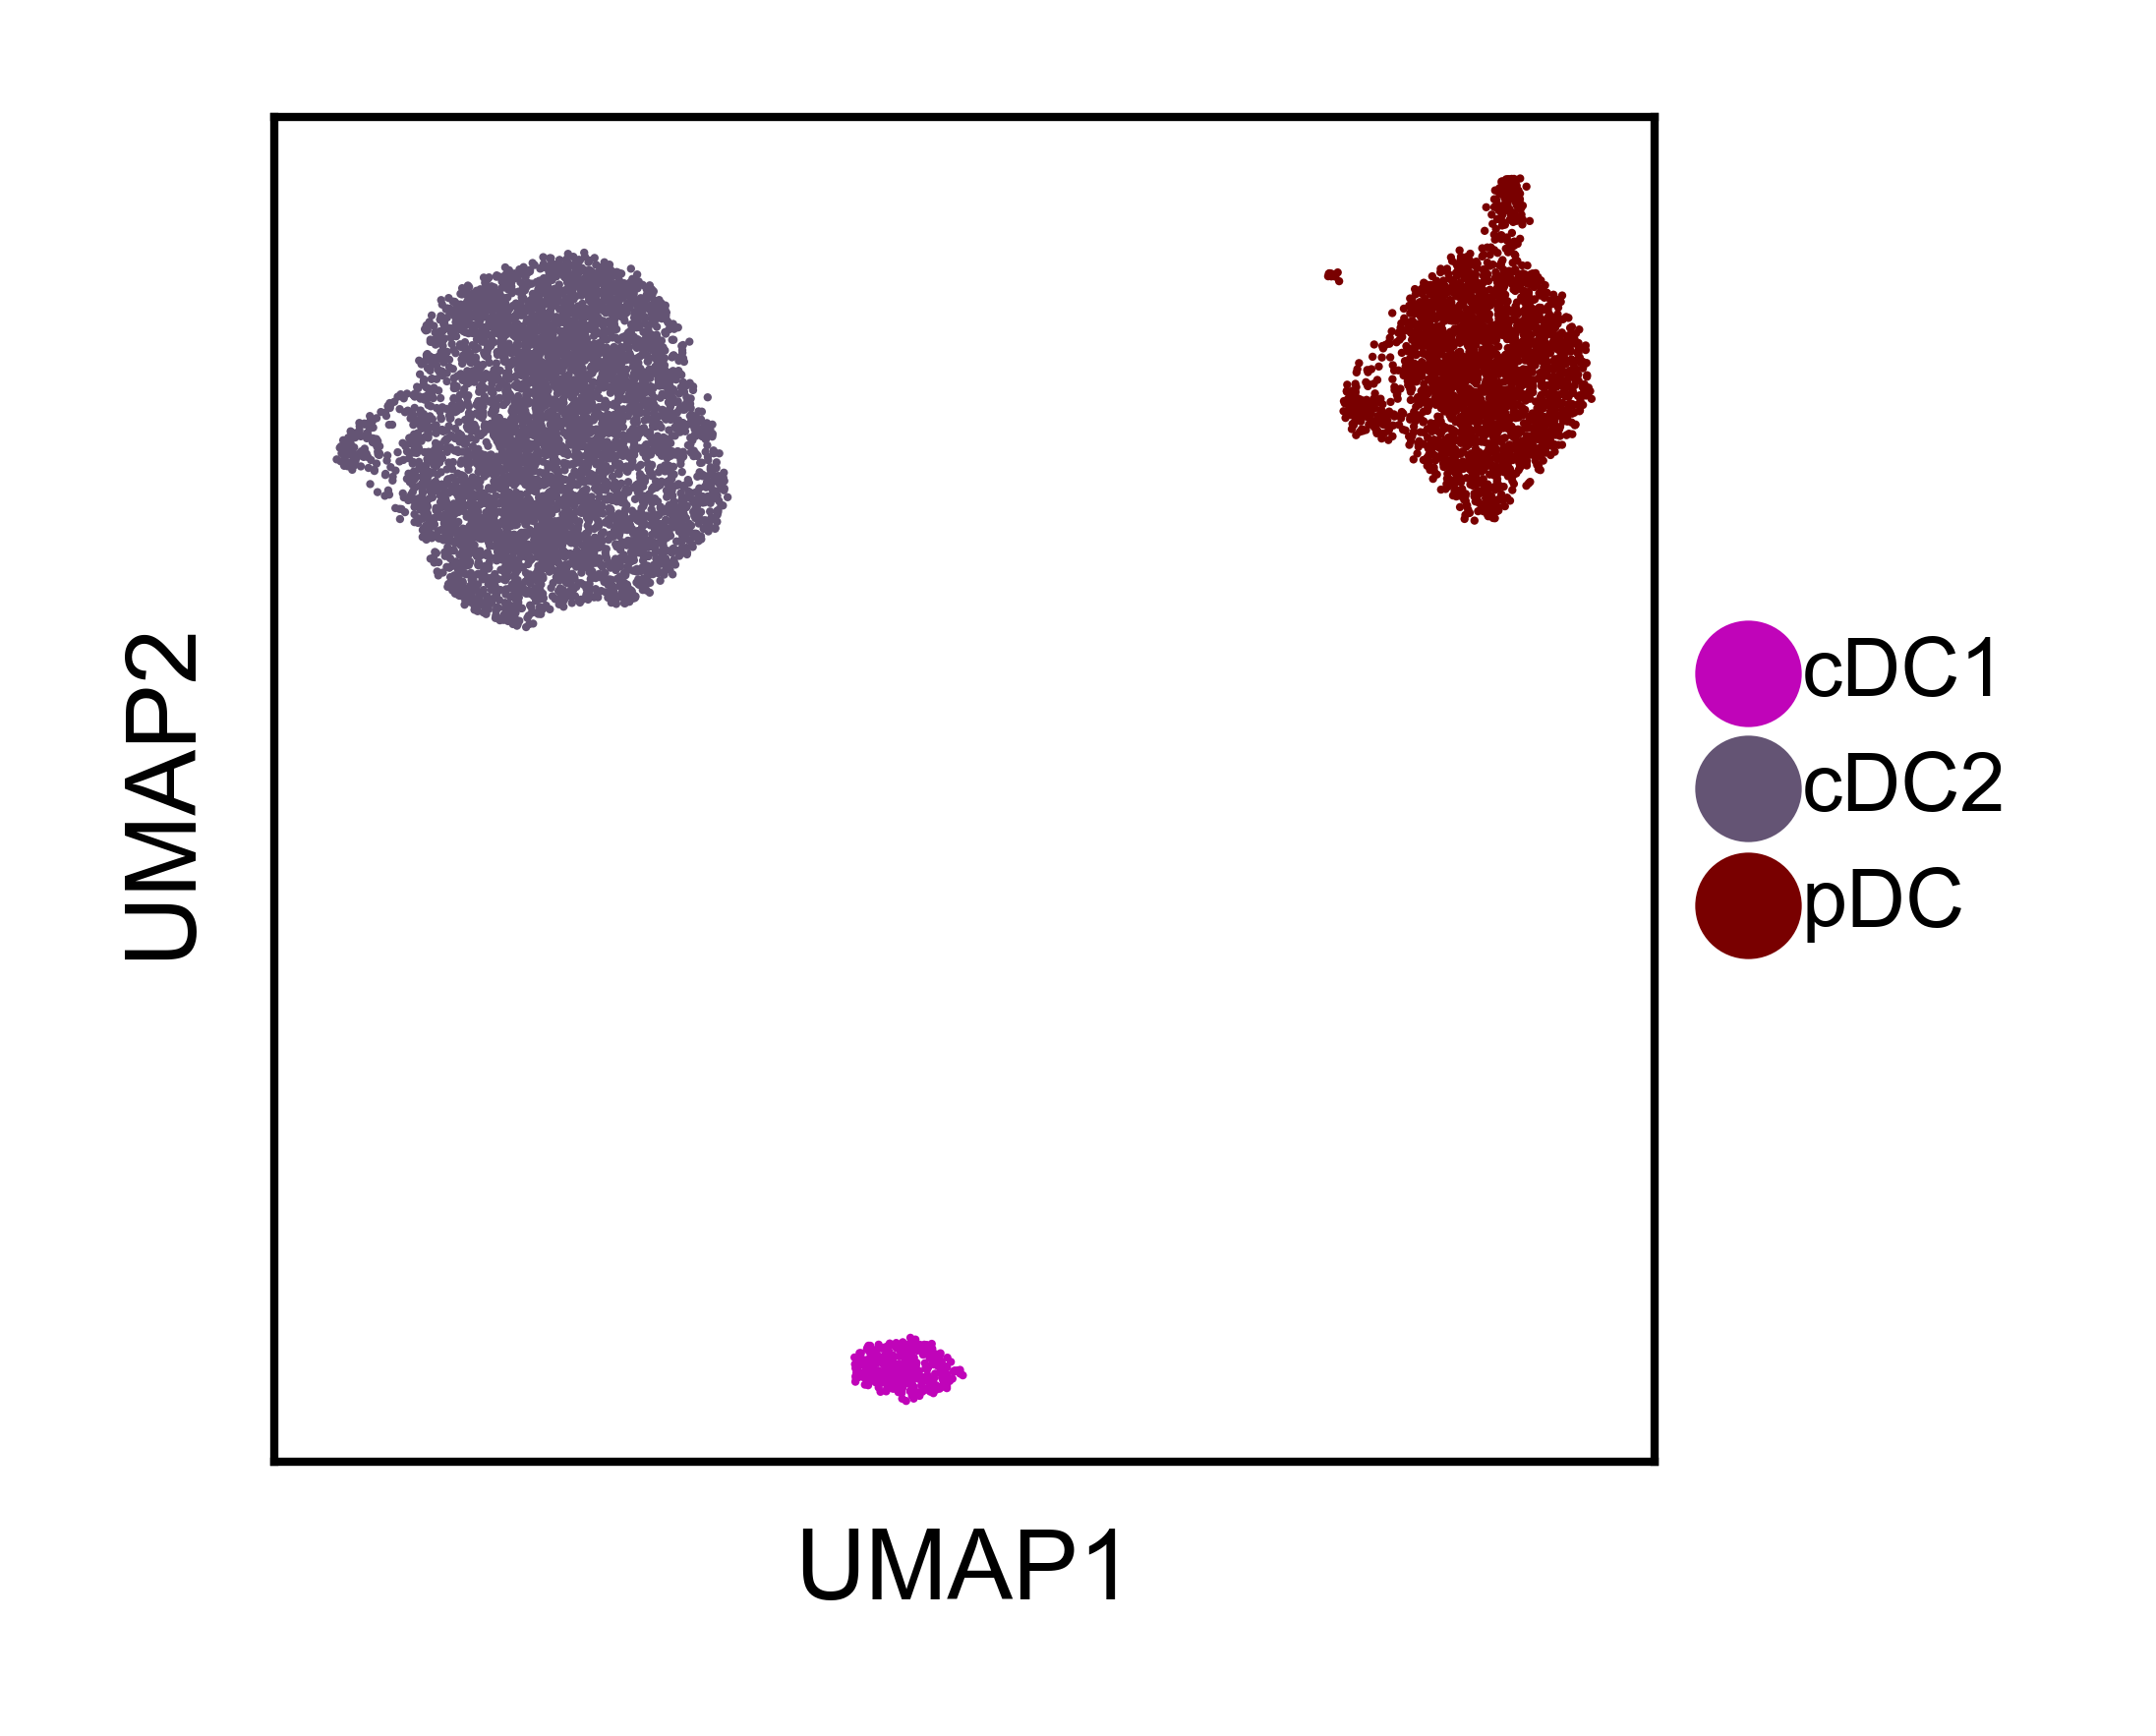

In [162]:
import scanpy as sc
fig, ax = plt.subplots(figsize=(1.5, 1.5))

covar = 'celltype_level3'


order = cells_group['DC']
pal_ordered = [palette_all[c] for c in order]


d.obs['celltype_level3_new'] = d.obs['celltype_level3'] 

sc.pl.umap(
    d,
    color='celltype_level3_new',
    palette=pal_ordered,
    size=1,
    ax=ax,
    legend_fontsize='small',
    # legend_loc='right',
    show=False,
    title=''
)

plt.savefig('plots/F6_2/DC_celltype.svg')

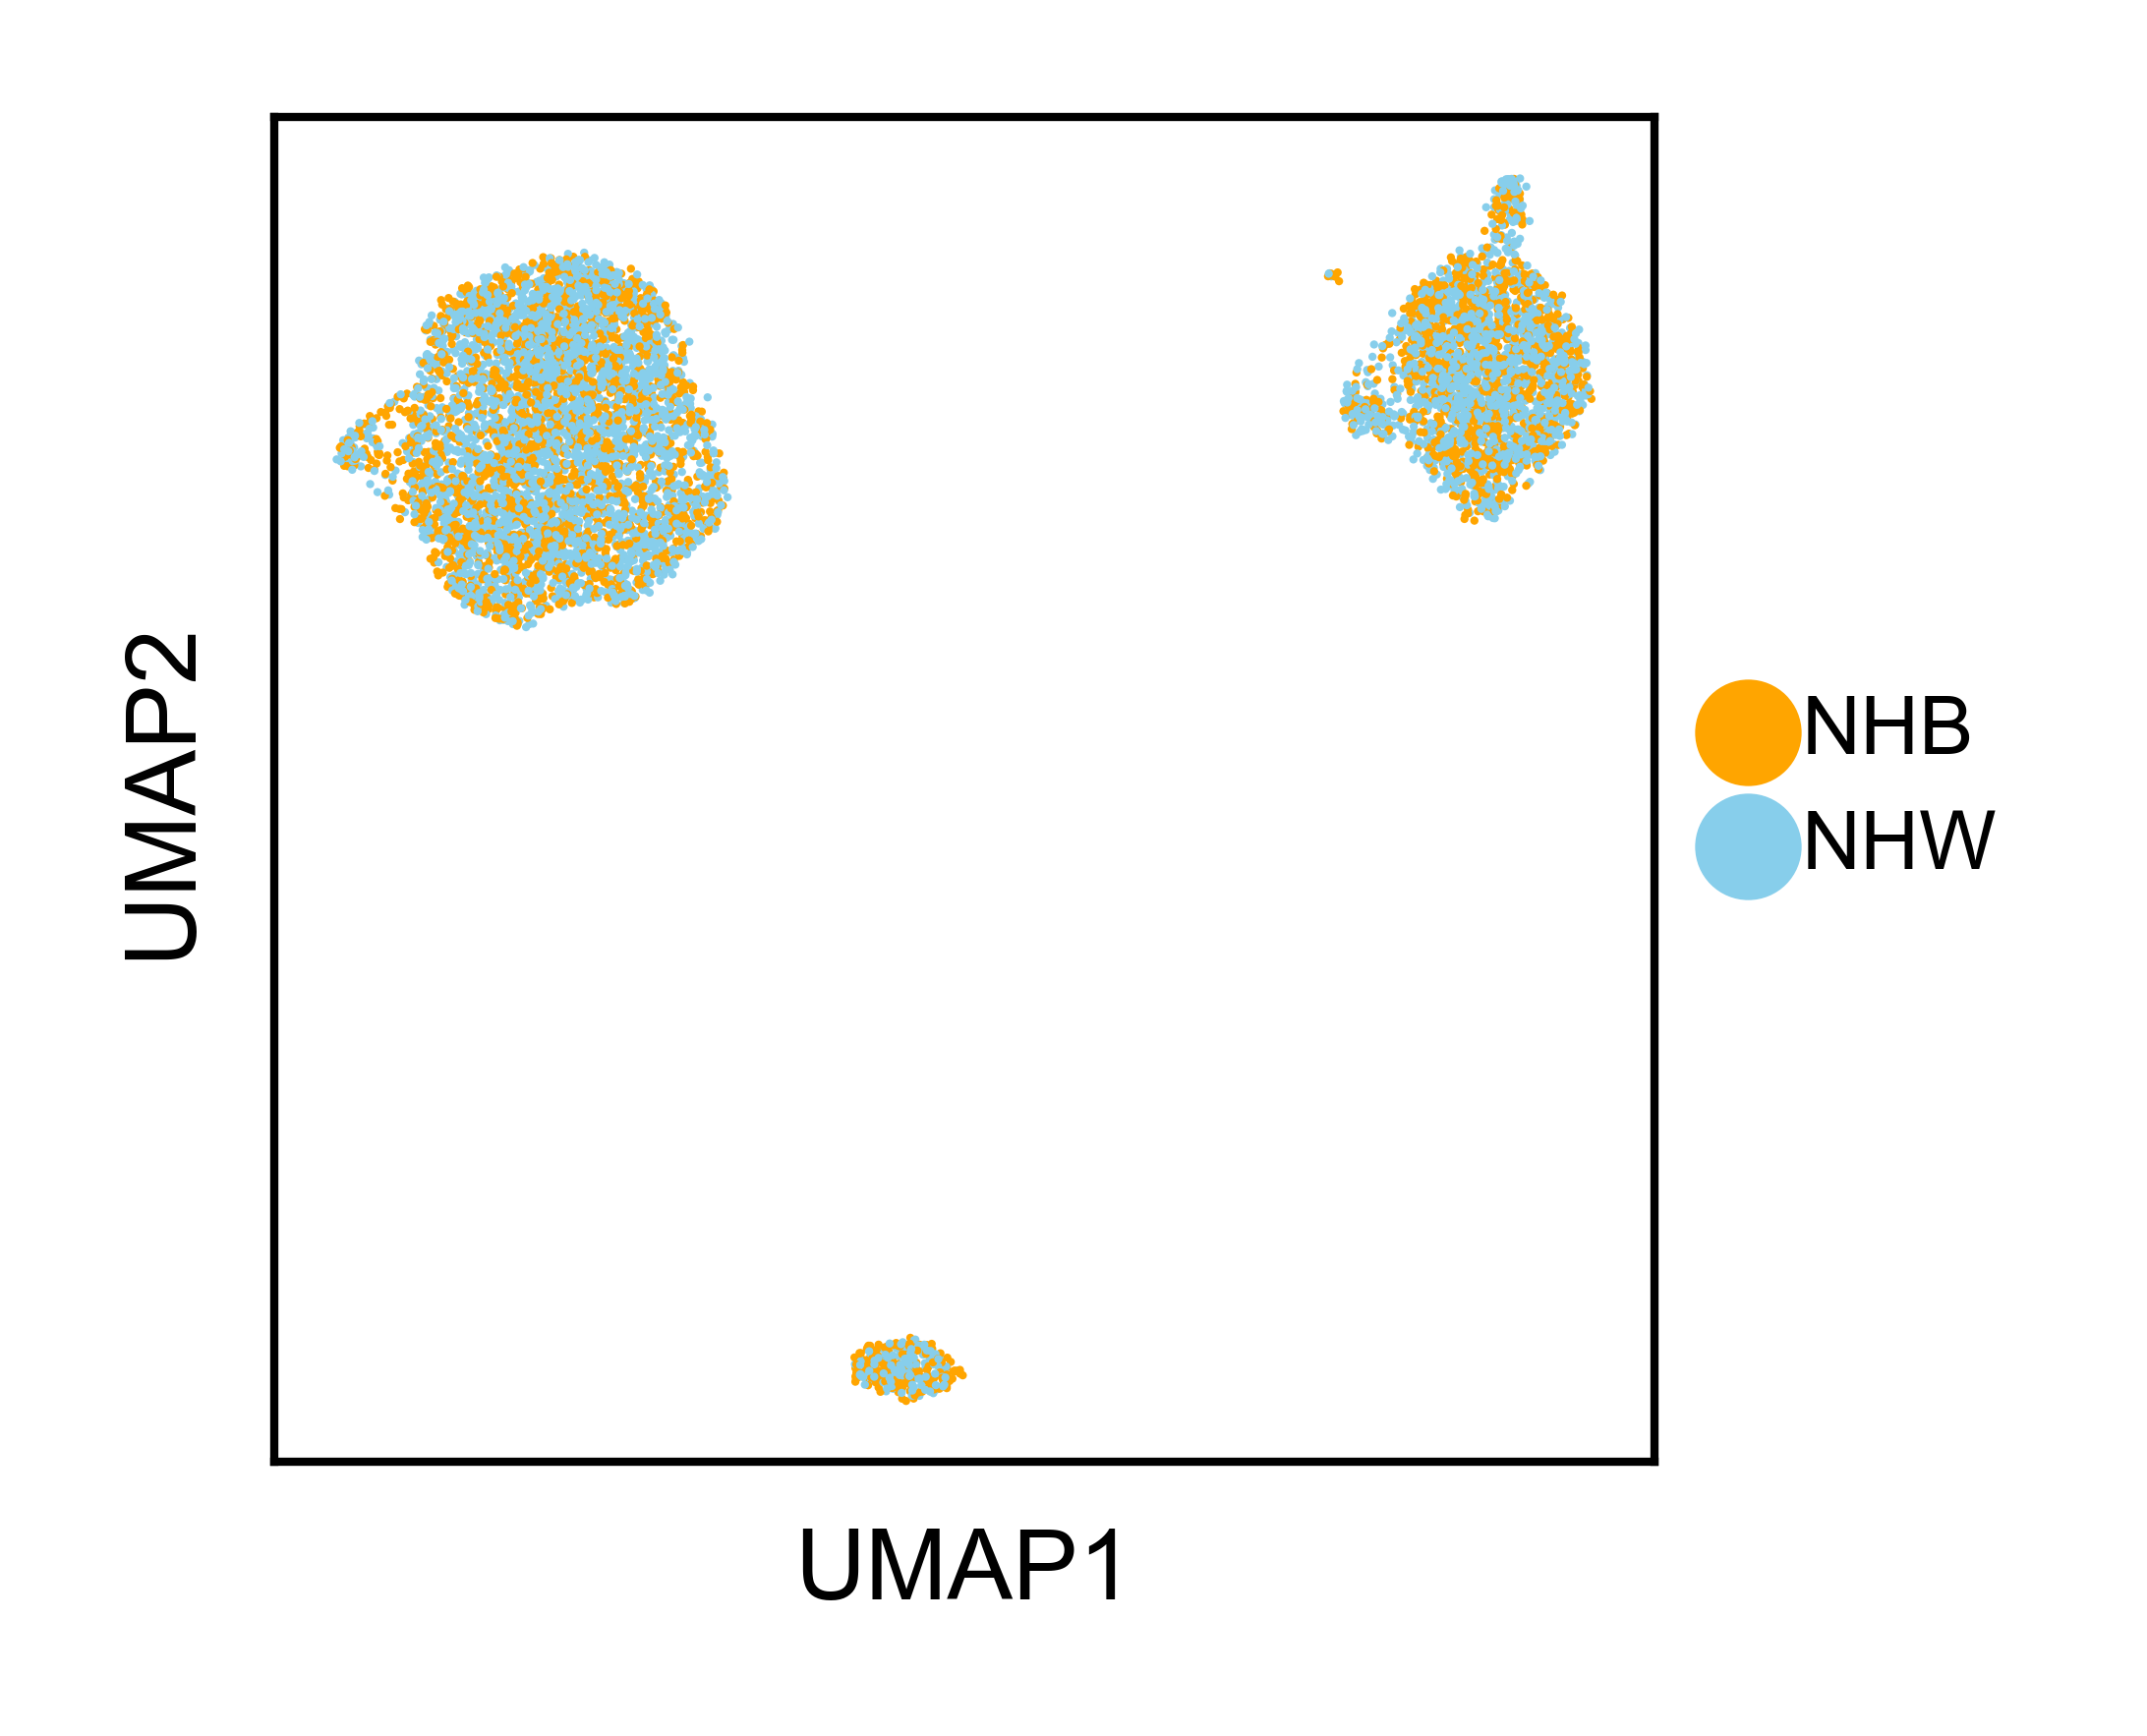

In [163]:
fig, ax = plt.subplots(figsize=(1.5, 1.5))

covar = 'race'
d.obs['race'] = [str(x).replace('1','NHB').replace('0','NHW') for x in d.obs['race']]

pal_ordered = [palette_all[c] for c in order]

sc.pl.umap(
    d,
    color=covar,
    palette=['orange','skyblue'],
    size=1,
    ax=ax,
    legend_fontsize='small',
    # legend_loc='right',
    show=False,
    title=''
)

plt.savefig('plots/F6_2/DC_race.svg')

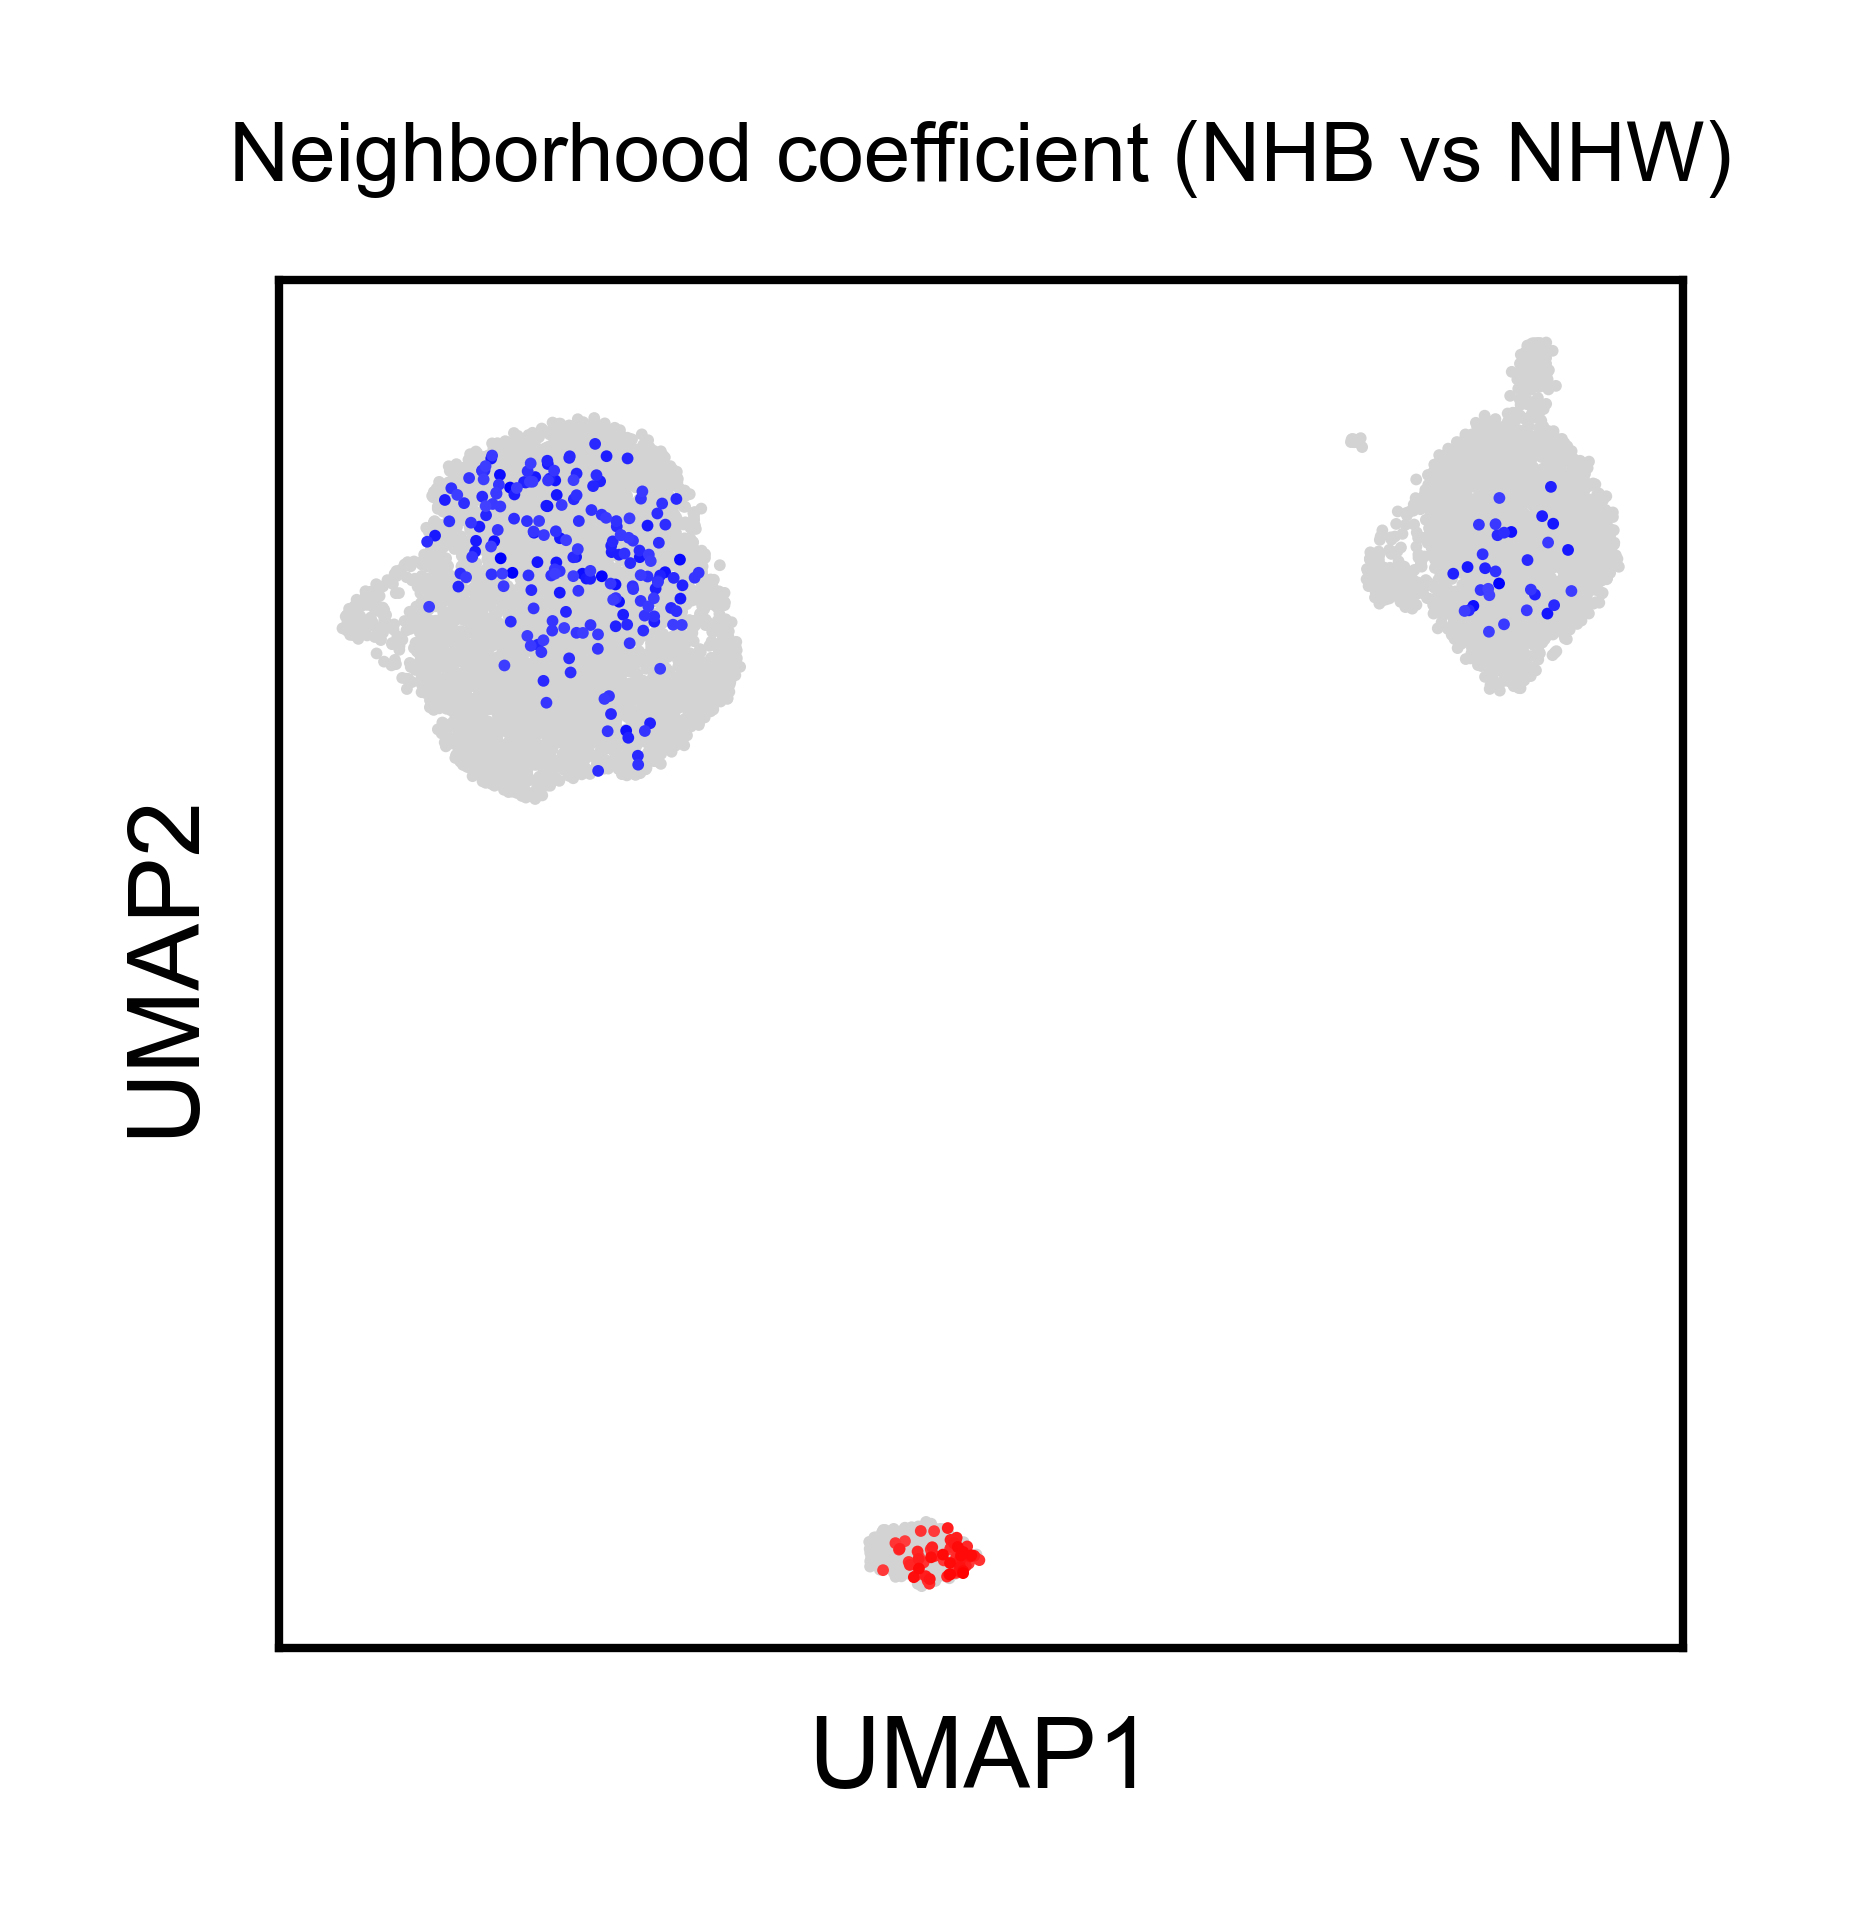

In [10]:
fig, ax = plt.subplots(figsize=(1.5, 1.5))

covar = 'race' 

coef_col = f"{covar}_coef"
fdr_col = f"{covar}_coef_fdr"
color_col = f"{covar}_coef_plot"

d.obs[color_col] = np.where(d.obs[fdr_col] < 0.1, d.obs[coef_col], np.nan)   # nan will show as gray in sc.pl.umap
sc.pl.umap(
    d,
    color=color_col,
    s=2,
    ax=ax,
    vmin=-1,
    vmax=1,
    cmap='seismic',
    na_color='lightgray',   # Gray for nan (non-significant)
    title='',
    colorbar_loc=None,
    show=False         # So you can further edit if needed
)

# cbar = ax.collections[0].colorbar
# ticks = [-1, -0.5, 0, 0.5, 1]
# cbar.set_ticks(ticks)
# cbar.set_ticklabels([str(t) for t in ticks])


ax.set_title('Neighborhood coefficient (NHB vs NHW)',fontsize=5)
plt.savefig('plots/F6_2/DC_NbCoeff.svg')

In [11]:
tmp = d[(d.obs[fdr_col]<0.1) & (d.obs[coef_col]>0)]
cnt = Counter(tmp.obs['celltype_level3'])
total = sum(cnt.values())

for k,v in cnt.items():
    print(f"{k}: {v} ({v/total*100:.2f}%)")

cDC1: 67 (100.00%)


In [12]:
tmp = d[(d.obs[fdr_col]<0.1) & (d.obs[coef_col]<0)]
cnt = Counter(tmp.obs['celltype_level3'])
total = sum(cnt.values())

for k,v in cnt.items():
    print(f"{k}: {v} ({v/total*100:.2f}%)")

cDC2: 198 (86.09%)
pDC: 32 (13.91%)


In [10]:
covar = 'race' 

coef_col = f"{covar}_coef"
fdr_col = f"{covar}_coef_fdr"
color_col = f"{covar}_coef_plot"


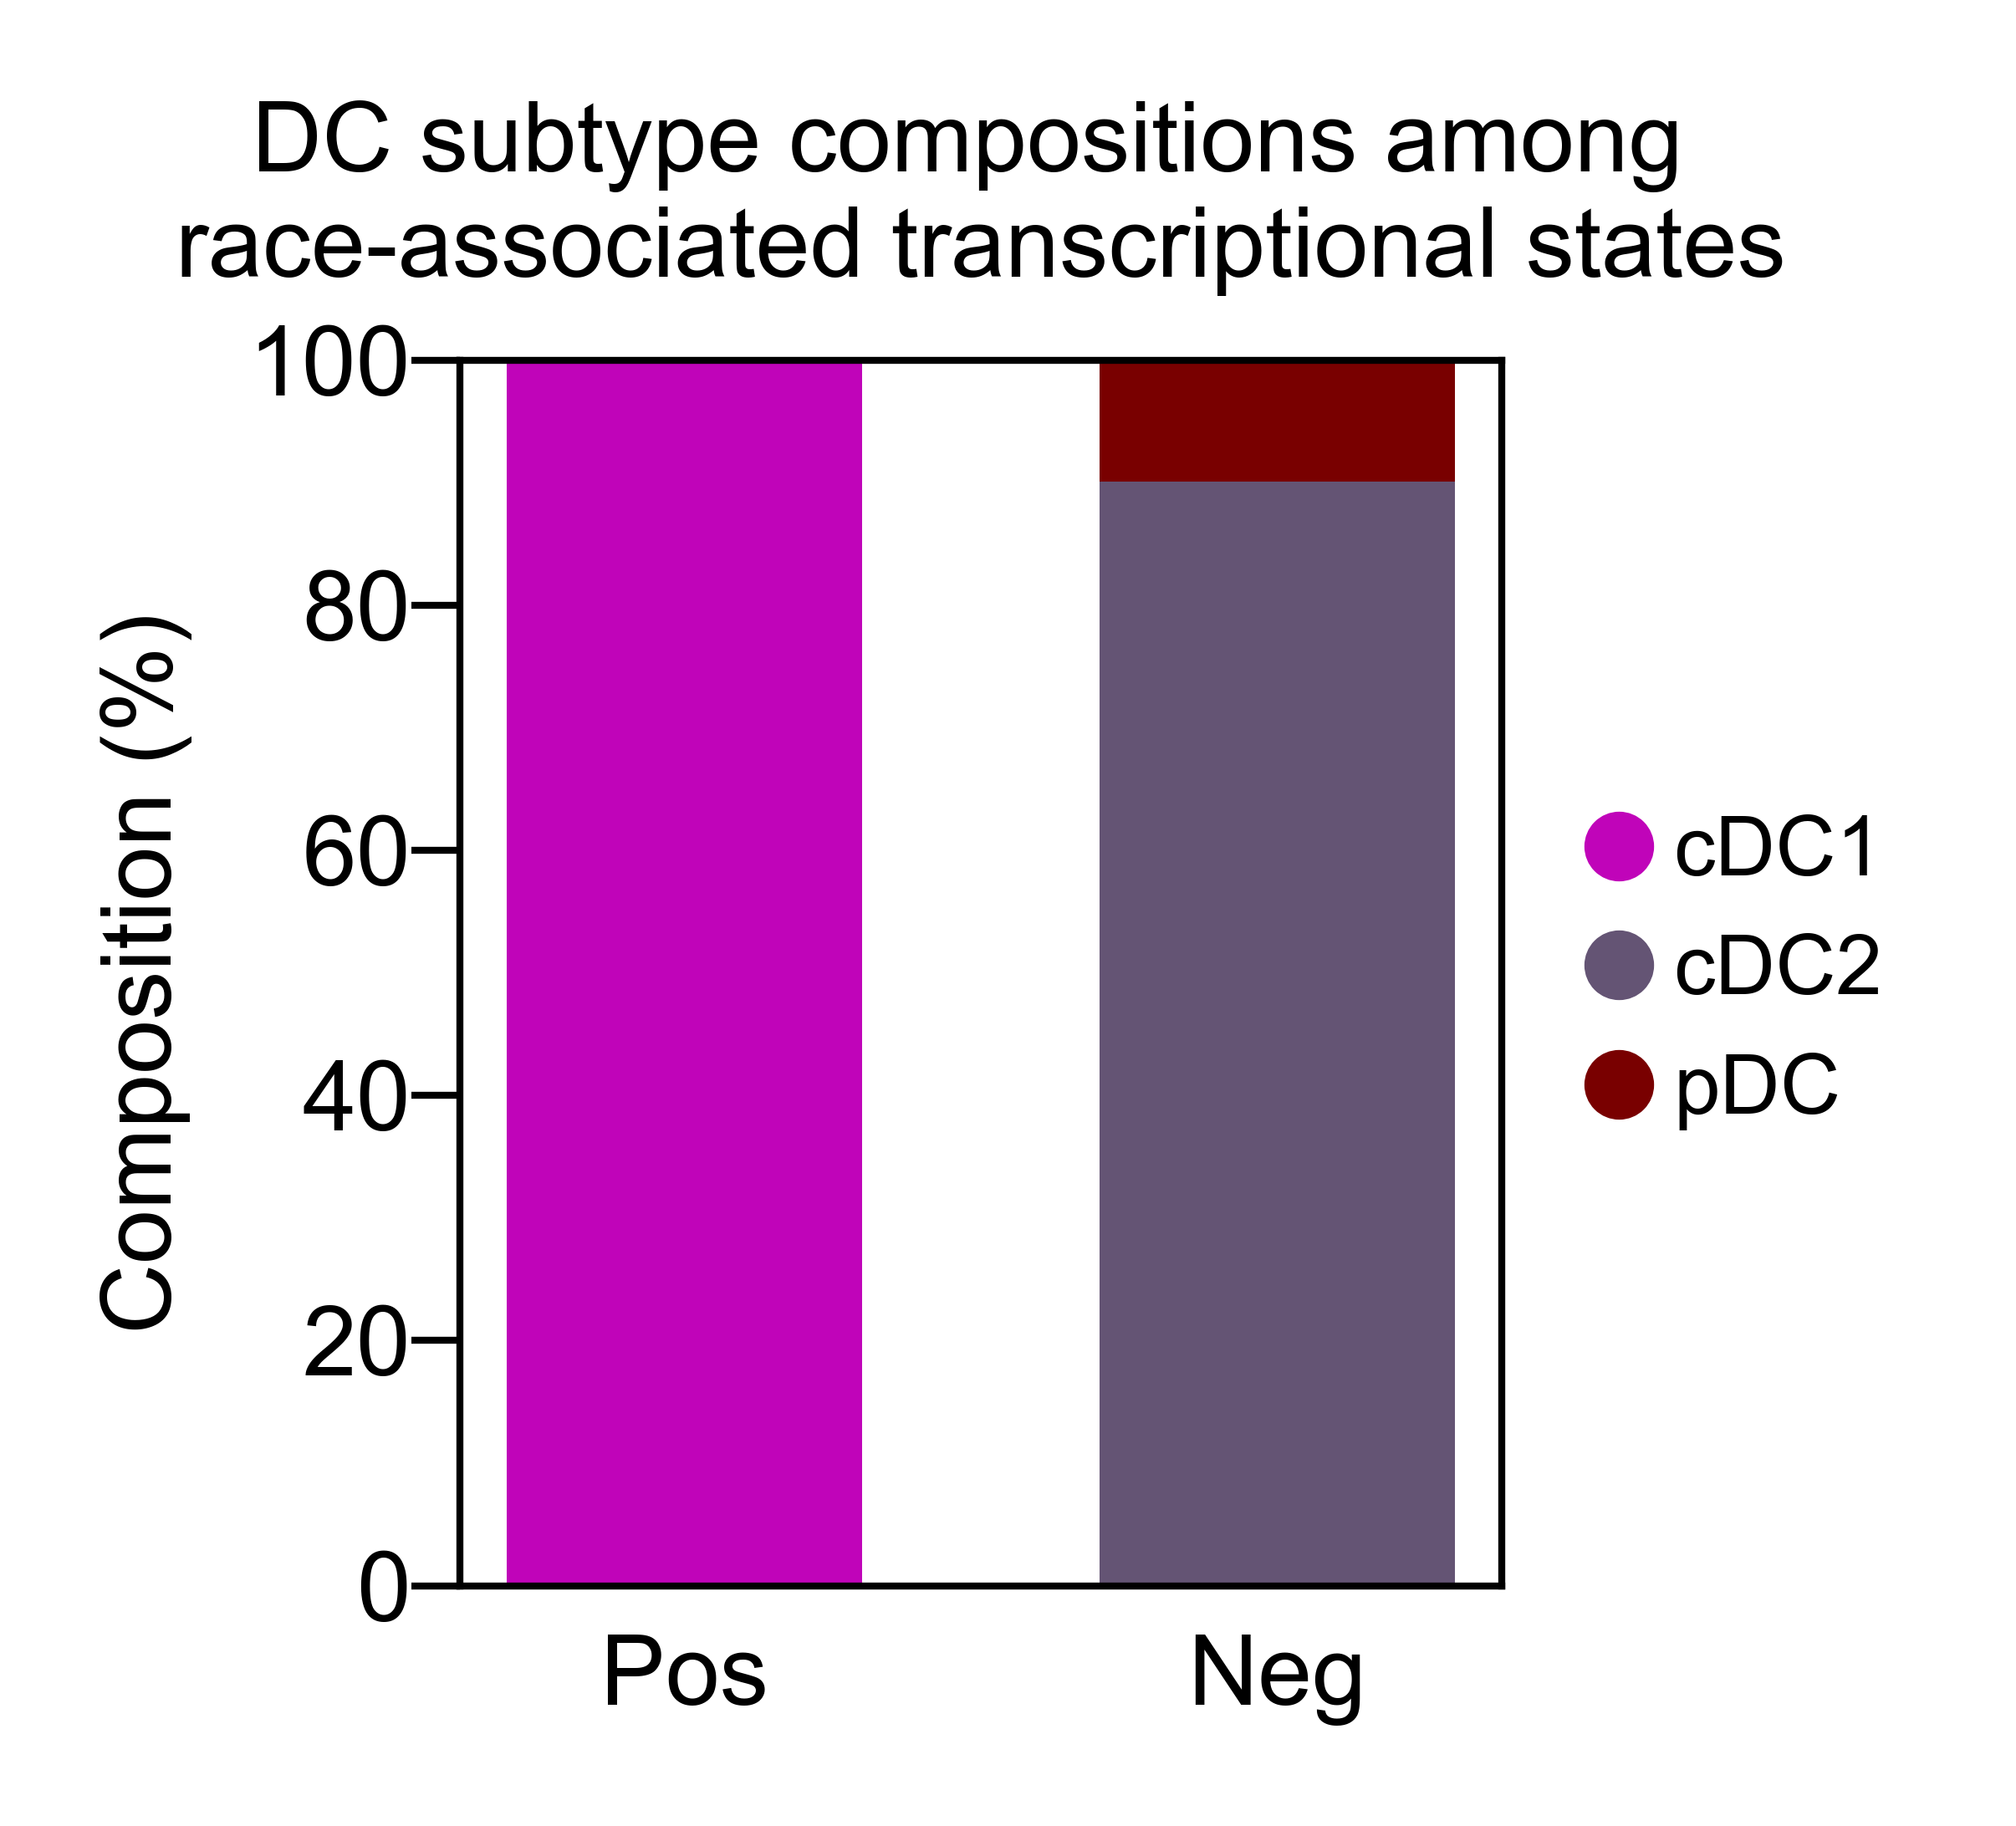

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

covar = "race"
fdr_col = f"{covar}_coef_fdr"
coef_col = f"{covar}_coef"

# positive-associated cells
tmp_pos = d[(d.obs[fdr_col] < 0.1) & (d.obs[coef_col] > 0)]
cnt_pos = Counter(tmp_pos.obs["celltype_level3"])

# negative-associated cells
tmp_neg = d[(d.obs[fdr_col] < 0.1) & (d.obs[coef_col] < 0)]
cnt_neg = Counter(tmp_neg.obs["celltype_level3"])

# all cell types appearing in either group
celltypes = sorted(set(cnt_pos.keys()) | set(cnt_neg.keys()))

# count table
df_counts = pd.DataFrame({
    "cell_type": celltypes,
    "pos_count": [cnt_pos.get(ct, 0) for ct in celltypes],
    "neg_count": [cnt_neg.get(ct, 0) for ct in celltypes],
})

# optional: keep only cell types present in your palette/order
celltype_order = [ct for ct in palette_all.keys() if ct in df_counts["cell_type"].values]
df_counts["cell_type"] = pd.Categorical(df_counts["cell_type"], categories=celltype_order, ordered=True)
df_counts = df_counts.sort_values("cell_type").reset_index(drop=True)

# calculate percentages within pos and neg separately
df_counts["pos_pct"] = df_counts["pos_count"] / df_counts["pos_count"].sum() * 100
df_counts["neg_pct"] = df_counts["neg_count"] / df_counts["neg_count"].sum() * 100

# reshape for plotting
dat = (
    df_counts
    .set_index("cell_type")[["pos_pct", "neg_pct"]]
    .T
)
dat.index = ["Pos", "Neg"]

# colors in desired order
pal_ordered = [palette_all[ct] for ct in dat.columns]

# plot
fig, ax = plt.subplots(figsize=(2,1.8))

bottom = pd.Series(0, index=dat.index)

for ct, color in zip(dat.columns, pal_ordered):
    ax.bar(
        dat.index,
        dat[ct],
        bottom=bottom,
        color=color,
        label=ct,
        width=0.6
    )
    bottom += dat[ct]

ax.set_ylabel("Composition (%)", fontsize=7)
ax.set_xlabel("")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", labelsize=7)
ax.tick_params(axis="y", labelsize=7)
ax.set_title('DC subtype compositions among \nrace-associated transcriptional states')


# plot legend
from matplotlib.lines import Line2D

label_map = {
    "cDC1": "cDC1",
    "cDC2": "cDC2",
    "pDC": "pDC"
}

handles = [
    Line2D(
        [0], [0],
        marker='o',
        linestyle='None',
        markerfacecolor=palette_all[ct],
        markeredgecolor=palette_all[ct],
        markersize=4,
        label=label_map.get(ct, ct)
    )
    for ct in dat.columns
]

ax.legend(
    handles=handles,
    title="",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=6,
    handletextpad=0.4
)

plt.tight_layout()
plt.savefig("plots/S4/DC_asso_composition.pdf", bbox_inches="tight")
plt.show()

In [15]:
df_counts

,cell_type,pos_count,neg_count,pos_pct,neg_pct
0,cDC1,67,0,100.0,0.000000
1,cDC2,0,198,0.0,86.086957
2,pDC,0,32,0.0,13.913043


## Disease State

In [9]:
cts = 0

for group in ['HRL','DCIS','BC']:

    for db in ['immport']:

        cts += 1
        
        raw = pd.read_csv(
            f'data/Figure6/CNArankNHBvsW_DC_{group}_{db}.csv', 
            index_col=0)
        
        dfp = raw#[raw['FDR q-val']<0.05].sort_values('NES', ascending=False)

        dfp['Tag %'] = (
            dfp['Tag %']
            .astype(str)
            .apply(lambda x: eval(x) if '/' in x else float(x))
        )
        dfp['Tag %'] = dfp['Tag %'] * 100
        dfp['log_p'] = -np.log10(dfp['FDR q-val'].replace(0, 1e-300))
        
        # Sort by NES
        dfp = dfp.sort_values('NES', ascending=False)
        
        # filter - 
        # dfp = dfp[dfp['Tag %']>=30]
        dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]


        dfp['analysis_group'] = [group]*dfp.shape[0]
        dfp['analysis_db'] = [db]*dfp.shape[0]

        out = dfp if cts==1 else pd.concat([out, dfp])


out        

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p,analysis_group,analysis_db
19,prerank,ANTIVIRAL INNATE IMMUNE RESPONSE,0.557093,1.485225,0.014563,0.767477,0.632,44.897959,15.03%,MX1;SMARCA5;PRKRA;EIF2AK2;UBE2W;IFIT2;MORC3;NM...,0.114935,HRL,immport
20,prerank,ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY,0.478571,1.463012,0.005365,0.505167,0.734,29.870130,11.67%,VAV3;RFTN1;CBLB;TNFRSF21;PDE4B;CD2AP;DENND1B;P...,0.296565,HRL,immport
22,prerank,COSTIMULATION BY THE CD28 FAMILY,0.528236,1.455201,0.016746,0.372338,0.763,53.731343,25.21%,BTLA;HLA-DQA1;RICTOR;PPP2R5C;THEM4;HLA-DQB1;LY...,0.429062,HRL,immport
24,prerank,INTERLEUKIN-20 FAMILY SIGNALING,0.625337,1.435024,0.038058,0.350950,0.834,22.727273,6.81%,IFNLR1;STAT1;STAT5B;STAT2;STAT4,0.454755,HRL,immport
27,prerank,NEGATIVE REGULATION OF CYTOPLASMIC PATTERN REC...,0.561466,1.421911,0.035354,0.320671,0.866,32.432432,15.31%,RAB7B;LILRA4;PTPRS;ITCH;PTPN22;PRKDC;CGAS;ERBI...,0.493940,HRL,immport
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8,prerank,ANTIMICROBIAL PEPTIDES,-0.634670,-1.470343,0.001040,0.102018,0.406,17.142857,3.56%,CCR2;RNASE6;S100A9;S100A8;TLR2;CD4,0.991325,BC,immport
7,prerank,INTERLEUKIN-20 FAMILY SIGNALING,-0.684893,-1.492205,0.006536,0.093286,0.314,68.181818,26.62%,JAK1;IFNLR1;TYK2;IL10RB;STAT2;STAT3;IFNL1;STAT...,1.030182,BC,immport
6,prerank,ROS AND RNS PRODUCTION IN PHAGOCYTES,-0.660576,-1.520216,0.001046,0.079041,0.214,54.285714,17.10%,ATP6V1B2;CYBB;HVCN1;NCF2;NCF4;ATP6V1A;ATP6V0D1...,1.102150,BC,immport
4,prerank,"COMPLEMENT ACTIVATION, LECTIN PATHWAY",-0.915026,-1.602146,0.001238,0.019301,0.040,16.666667,0.12%,FCN1,1.714429,BC,immport


### HRL

In [10]:
DzState, db = 'HRL', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['NUCLEOTIDE-BINDING DOMAIN, LEUCINE RICH REPEAT CONTAINING RECEPTOR (NLR) SIGNALING PATHWAYS',
       'IMMUNE RESPONSE TO TUMOR CELL',
       'ANTIBODY-DEPENDENT CELLULAR CYTOTOXICITY',
       'LEUKOCYTE MEDIATED CYTOTOXICITY',
       'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY',
       'NEGATIVE REGULATION OF HEMOPOIESIS', 'LEUKOCYTE CHEMOTAXIS',
       'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS',
       'LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY RESPONSE',
       'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
       'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
       'COMPLEMENT ACTIVATION, LECTIN PATHWAY',
       'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
       'INTERLEUKIN-10 SIGNALING', 'INNATE IMMUNE RESPONSE IN MUCOSA',
       'ANTIMICROBIAL PEPTIDES',
       'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
       'ANTIMICROBIAL HUMORAL RESPONSE', 'NEUTROPHIL DEGRANULATION'],
      dtype=object)

In [11]:
paths_relevant = [
'NUCLEOTIDE-BINDING DOMAIN, LEUCINE RICH REPEAT CONTAINING RECEPTOR (NLR) SIGNALING PATHWAYS',
'IMMUNE RESPONSE TO TUMOR CELL', 
'LEUKOCYTE MEDIATED CYTOTOXICITY',
'ANTIBODY-DEPENDENT CELLULAR CYTOTOXICITY',
'LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY RESPONSE',
'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY',
'NEGATIVE REGULATION OF HEMOPOIESIS',
'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS',
# 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE', 
'LEUKOCYTE CHEMOTAXIS',
'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
'COMPLEMENT ACTIVATION, LECTIN PATHWAY',
'INTERLEUKIN-10 SIGNALING',
'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
# 'INNATE IMMUNE RESPONSE IN MUCOSA', 
'ANTIMICROBIAL PEPTIDES',
'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
'ANTIMICROBIAL HUMORAL RESPONSE'#,
# 'NEUTROPHIL DEGRANULATION'    
]

In [12]:
dfp_sel = dfp[dfp['Term'].isin(paths_relevant)]
dfp_sel.to_csv(f'data/Tables/DC_{DzState}.csv')

In [121]:
short_name_map = {
    'NUCLEOTIDE-BINDING DOMAIN, LEUCINE RICH REPEAT CONTAINING RECEPTOR (NLR) SIGNALING PATHWAYS':
        'NLR SIG PATHWAYS',
    'IMMUNE RESPONSE TO TUMOR CELL':
        'IMMUNE RESP TO TUMOR CELL',
    'LEUKOCYTE MEDIATED CYTOTOXICITY':
        'LEUKO MEDIATED CYTOTOX',
    'ANTIBODY-DEPENDENT CELLULAR CYTOTOXICITY':
        'AB-DEP CELLULAR CYTOTOX',
    'LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY RESPONSE':
        'LEUKO ACTIV IN INFLAMM RESP',
    'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY':
        'INNATE RESP ACTIV CELL SURF R SIG',
    'NEGATIVE REGULATION OF HEMOPOIESIS':
        'NEG REG OF HEMOPOIESIS',
    'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS':
        'INFLAMM RESP TO AG STIMULUS',
    'LEUKOCYTE CHEMOTAXIS':
        'LEUKO CHEMOTAXIS',
    'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL':
        'IMMUNOREG BET LYMPHOID-NON-LYMPHOID',
    'COMPLEMENT ACTIVATION, LECTIN PATHWAY':
        'COMPLEMENT ACTIV, LECTIN PATHWAY',
    'INTERLEUKIN-10 SIGNALING':
        'IL-10 SIG',
    'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE':
        'LEUKO MIGR IN INFLAMM RESP',
    'ANTIMICROBIAL PEPTIDES':
        'ANTIMICROBIAL PEPTIDES',
    'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING':
        'IL-4, IL-13 SIG',
    'ANTIMICROBIAL HUMORAL RESPONSE':
        'ANTIMICROBIAL HUMORAL RESP'
}


In [122]:
triangle_map = {
    'NUCLEOTIDE-BINDING DOMAIN, LEUCINE RICH REPEAT CONTAINING RECEPTOR (NLR) SIGNALING PATHWAYS':
        {"marker": "v", "color": "#5E4FA2"},

    'IMMUNE RESPONSE TO TUMOR CELL':
        {"marker": "v", "color": "#F46D1F"},

    'LEUKOCYTE MEDIATED CYTOTOXICITY':
        {"marker": "v", "color": "#5E4FA2"},

    'ANTIBODY-DEPENDENT CELLULAR CYTOTOXICITY':
        {"marker": "v", "color": "#F46D1F"},

    'LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY RESPONSE':
        {"marker": "v", "color": "#5E4FA2"},

    'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY':
        {"marker": "v", "color": "#5E4FA2"},

    'NEGATIVE REGULATION OF HEMOPOIESIS':
        {"marker": "v", "color": "#FDBF11"},

    'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS':
        {"marker": "v", "color": "#F46D1F"},

    'LEUKOCYTE CHEMOTAXIS':
        {"marker": "v", "color": "#009E57"},

    'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL':
        {"marker": "v", "color": "#F46D1F"},

    'COMPLEMENT ACTIVATION, LECTIN PATHWAY':
        {"marker": "v", "color": "#D7191C"},

    'INTERLEUKIN-10 SIGNALING':
        {"marker": "v", "color": "#5E4FA2"},

    'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE':
        {"marker": "v", "color": "#009E57"},

    'ANTIMICROBIAL PEPTIDES':
        {"marker": "v", "color": "#7B4F2A"},

    'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING':
        {"marker": "v", "color": "#F46D1F"},

    'ANTIMICROBIAL HUMORAL RESPONSE':
        {"marker": "v", "color": "#7B4F2A"}
}

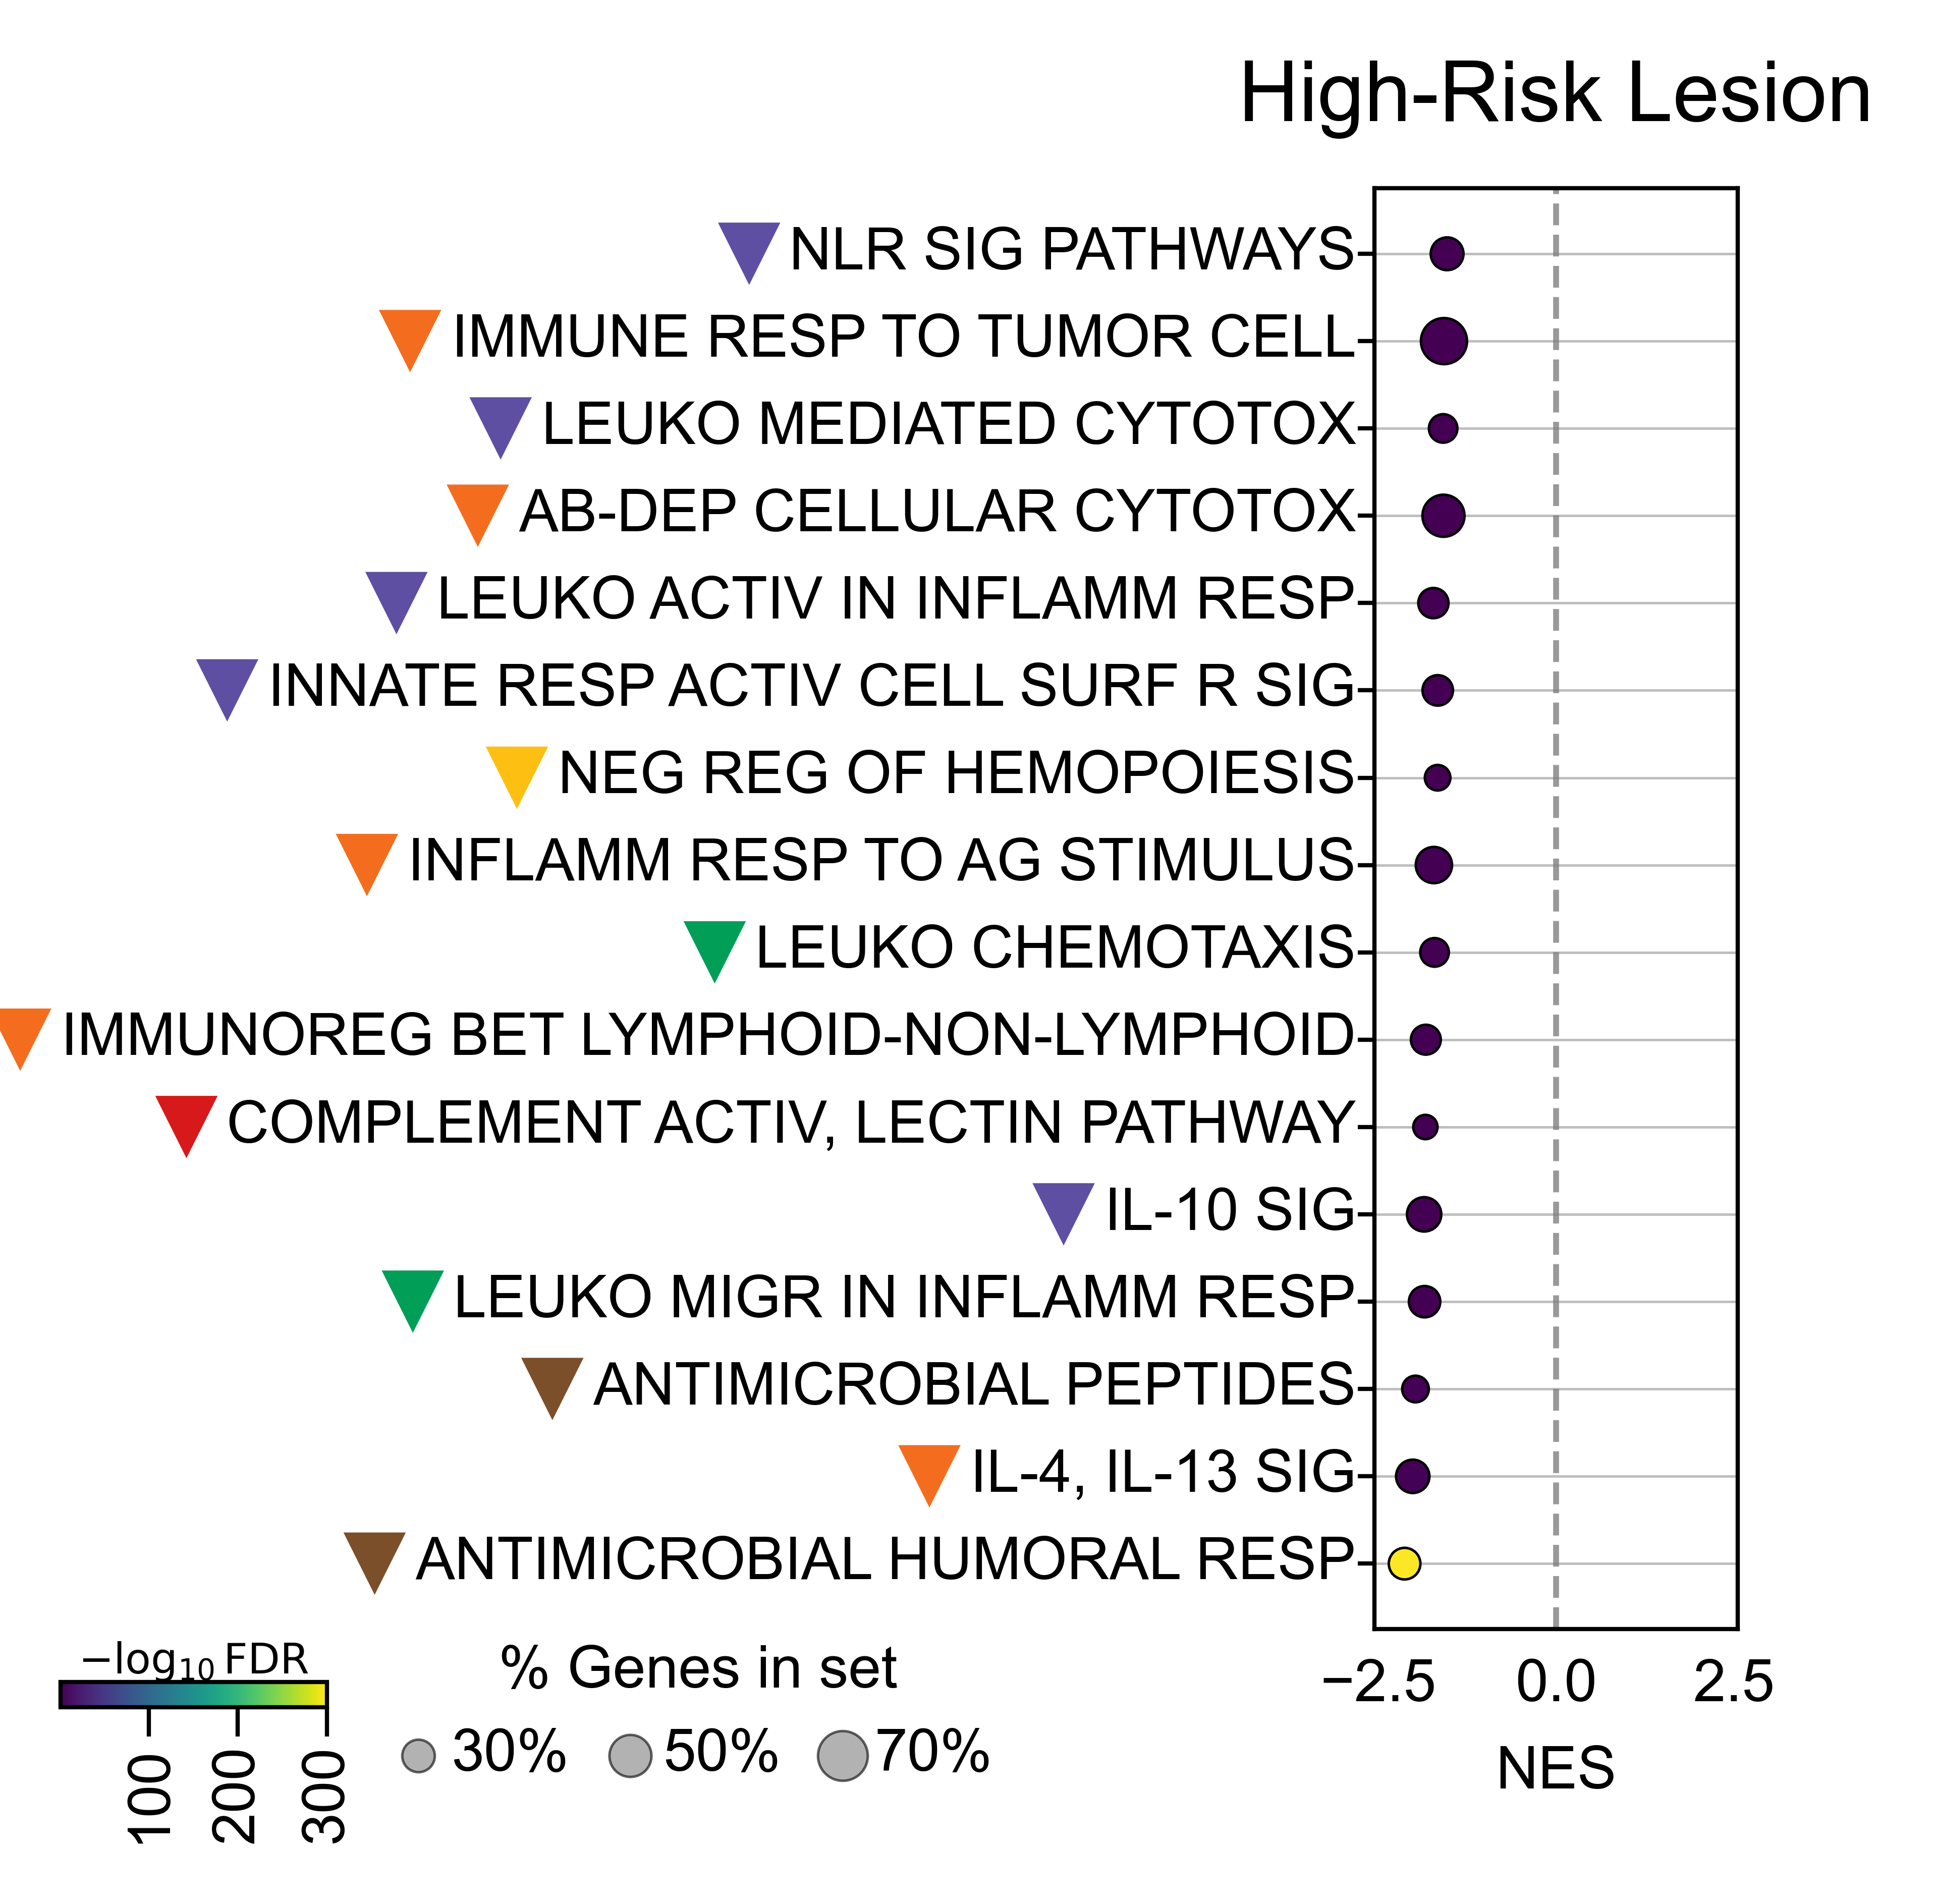

In [132]:
import pandas as pd
import matplotlib.pyplot as plt
from textwrap import fill
from matplotlib import font_manager as fm

title_map = {"HRL": "High-Risk Lesion", "DCIS": "DCIS", "BC": "Breast Cancer"}

# -----------------------------
# Prepare data
# -----------------------------
dfp2 = dfp[dfp["Term"].isin(paths_relevant)].copy()
dfp2["Term"] = pd.Categorical(dfp2["Term"], categories=paths_relevant, ordered=True)
dfp2 = dfp2.sort_values("Term").reset_index(drop=True)

dfp2["Term_full"] = dfp2["Term"].astype(str)
dfp2["Term_short"] = dfp2["Term_full"].map(short_name_map).fillna(dfp2["Term_full"])
dfp2["Term_plot"] = dfp2["Term_short"].apply(lambda x: fill(str(x), width=38))

# -----------------------------
# Parameters
# -----------------------------
dot_scale = 0.5
cmap = plt.cm.viridis
arial_font = fm.FontProperties(family="Arial")

label_fontsize = 7
label_right_x = -0.05

triangle_gap_px = 30
triangle_size = 55
triangle_half_width_px = 10

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(2, 3.5))

# Main control:
# larger left = wider ylabel region + narrower bubble box
fig.subplots_adjust(left=0.68, right=0.98, bottom=0.24, top=0.92)

ypos = list(range(len(dfp2)))

sc = ax.scatter(
    dfp2["NES"],
    ypos,
    s=dfp2["Tag %"] * dot_scale,
    c=dfp2["log_p"],
    cmap=cmap,
    edgecolor="black",
    linewidth=0.3,
    zorder=3
)

# -----------------------------
# Manual y labels
# -----------------------------
ax.set_yticks(ypos)
ax.set_yticklabels([])
ax.invert_yaxis()

label_text_objects = []

for i, row in dfp2.iterrows():
    txt = ax.text(
        label_right_x,
        i,
        row["Term_plot"],
        transform=ax.get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=label_fontsize,
        clip_on=False
    )
    label_text_objects.append((txt, row["Term_full"], i))

# -----------------------------
# Axes formatting
# -----------------------------
nes_max = dfp2["NES"].abs().max()
nes_min = dfp2["NES"].min()
ax.set_xlim([nes_min * 1.2, nes_max * 1.2])

ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis="x", labelsize=7)
ax.tick_params(axis="y", length=2, labelsize=6, pad=1)
ax.set_title(title_map.get(DzState, DzState), fontsize=10, pad=8)

ax.grid(axis="y", linestyle="-", linewidth=0.3, color="gray", alpha=0.5, zorder=0)
ax.axvline(x=0, linestyle="--", linewidth=0.7, color="gray", alpha=0.8, zorder=1)

# -----------------------------
# Draw once, then measure manual labels
# -----------------------------
fig.canvas.draw()
renderer = fig.canvas.get_renderer()

label_bboxes = [
    txt.get_window_extent(renderer=renderer)
    for txt, term_full, i in label_text_objects
]

leftmost_label_x_display = min(b.x0 for b in label_bboxes)
lowest_label_y_display = min(b.y0 for b in label_bboxes)

leftmost_label_x_fig, lowest_label_y_fig = fig.transFigure.inverted().transform(
    (leftmost_label_x_display, lowest_label_y_display)
)

# -----------------------------
# Triangles immediately left of labels
# -----------------------------
for txt, term_full, i in label_text_objects:
    tri = triangle_map.get(term_full)
    if tri is None:
        continue

    bbox = txt.get_window_extent(renderer=renderer)
    triangle_x_display = bbox.x0 - triangle_gap_px - triangle_half_width_px
    triangle_x_axes = ax.transAxes.inverted().transform((triangle_x_display, bbox.y0))[0]

    ax.scatter(
        triangle_x_axes,
        i,
        marker=tri["marker"],
        s=triangle_size,
        color=tri["color"],
        edgecolor="none",
        transform=ax.get_yaxis_transform(),
        clip_on=False,
        zorder=5
    )

# -----------------------------
# Colorbar: left aligned to leftmost ylabel
# -----------------------------
cbar_left = leftmost_label_x_fig
cbar_bottom = lowest_label_y_fig - 0.055
cbar_width = 0.22
cbar_height = 0.012

cax = fig.add_axes([cbar_left, cbar_bottom, cbar_width, cbar_height])

cbar = fig.colorbar(sc, cax=cax, orientation="horizontal")
cbar.set_label(
    r"$-\log_{10}\mathrm{FDR}$",
    fontproperties=arial_font,
    fontsize=5,
    labelpad=1
)
cbar.ax.xaxis.set_label_position("top")
cbar.ax.xaxis.set_ticks_position("bottom")
cbar.ax.tick_params(labelsize=7, pad=1, rotation=90)
cbar.solids.set_rasterized(True)

# -----------------------------
# Bubble legend: right of colorbar
# -----------------------------
size_handles = [
    plt.scatter(
        [], [],
        s=size * dot_scale,
        c="gray",
        alpha=0.6,
        edgecolor="black",
        linewidth=0.3
    )
    for size in [30, 50, 70]
]

bubble_legend_x = cbar_left + cbar_width * 1.2
bubble_legend_y = cbar_bottom - 0.003

leg = fig.legend(
    size_handles,
    ["30%", "50%", "70%"],
    title="% Genes in set",
    title_fontsize=7,
    fontsize=7,
    frameon=False,
    loc="center left",
    bbox_to_anchor=(bubble_legend_x, bubble_legend_y),
    ncol=3,
    columnspacing=0.8,
    handletextpad=0.3,
    borderaxespad=0
)

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    f"plots/F5/Bubble_DC_{DzState}.png",
    bbox_inches="tight",
    pad_inches=0.2, 
    dpi=600
)

plt.show()

### DCIS

In [13]:
DzState, db = 'DCIS', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['COMPLEMENT CASCADE', 'FC EPSILON RECEPTOR (FCERI) SIGNALING',
       'ADAPTIVE IMMUNE RESPONSE BASED ON SOMATIC RECOMBINATION OF IMMUNE RECEPTORS BUILT FROM IMMUNOGLOBULIN SUPERFAMILY DOMAINS',
       'LEUKOCYTE MEDIATED CYTOTOXICITY',
       'NEGATIVE REGULATION OF ANTIGEN PROCESSING AND PRESENTATION',
       'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY',
       'ACTIVATION OF INNATE IMMUNE RESPONSE',
       'INTERLEUKIN-12 FAMILY SIGNALING',
       'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY',
       'TYPE 2 IMMUNE RESPONSE', 'C-TYPE LECTIN RECEPTORS (CLRS)',
       'LEUKOCYTE CHEMOTAXIS', 'DAP12 INTERACTIONS',
       'MYELOID LEUKOCYTE ACTIVATION', 'ANTIMICROBIAL HUMORAL RESPONSE',
       'BUTYROPHILIN (BTN) FAMILY INTERACTIONS',
       'INTERLEUKIN-1 FAMILY SIGNALING',
       'NEGATIVE REGULATION OF IMMUNE RESPONSE', 'TCR SIGNALING',
       'INTERFERON GAMMA SIGNALING',
       'LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY RESPONSE',
 

In [14]:
paths_relevant = [
    'COMPLEMENT CASCADE',  # relevant: DCs can respond to complement/inflammatory opsonization signals; broad but interpretable in myeloid/DC context

    'FC EPSILON RECEPTOR (FCERI) SIGNALING',  # relevant/conditional: Fc receptor signaling can be relevant to myeloid DC activation, but inspect genes to ensure not mast/basophil contamination

    # 'ADAPTIVE IMMUNE RESPONSE BASED ON SOMATIC RECOMBINATION OF IMMUNE RECEPTORS BUILT FROM IMMUNOGLOBULIN SUPERFAMILY DOMAINS',  # not DC-specific: sounds B/T receptor recombination biology rather than DC-intrinsic function

    # 'LEUKOCYTE MEDIATED CYTOTOXICITY',  # not ideal for DCs: more NK/CD8/cytotoxic lymphocyte biology; keep only if leading-edge genes are DC-associated cytotoxic/inflammatory genes

    'NEGATIVE REGULATION OF ANTIGEN PROCESSING AND PRESENTATION',  # relevant: directly tied to DC antigen presentation capacity and immune regulation

    'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY',  # relevant: captures PRR/FcR/myeloid receptor-mediated activation in DCs

    'ACTIVATION OF INNATE IMMUNE RESPONSE',  # relevant: core DC function, especially peripheral blood innate activation state

    'INTERLEUKIN-12 FAMILY SIGNALING',  # relevant: DCs are major regulators/producers/responders in IL-12/IL-23-type inflammatory axis

    'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY',  # relevant but redundant with innate activation terms; keep if leading-edge genes are distinct

    'TYPE 2 IMMUNE RESPONSE',  # relevant/conditional: DCs can prime type 2 immunity, but may also reflect T helper/eosinophil/basophil biology; inspect leading-edge genes

    'C-TYPE LECTIN RECEPTORS (CLRS)',  # highly relevant: CLR-mediated antigen uptake/sensing is canonical DC/myeloid biology

    'LEUKOCYTE CHEMOTAXIS',  # relevant: DC trafficking/chemokine response and inflammatory recruitment context

    'DAP12 INTERACTIONS',  # relevant: immunoreceptor adaptor signaling in myeloid/DC activation

    'MYELOID LEUKOCYTE ACTIVATION',  # relevant: DCs are myeloid leukocytes; broad but appropriate

    # 'ANTIMICROBIAL HUMORAL RESPONSE',  # weak for DCs: more soluble antimicrobial/epithelial/neutrophil/plasma-associated; keep only if leading-edge genes are DC-expressed

    'BUTYROPHILIN (BTN) FAMILY INTERACTIONS',  # relevant/conditional: immune regulatory ligand interactions; keep if leading-edge genes support APC/T-cell crosstalk interpretation

    'INTERLEUKIN-1 FAMILY SIGNALING',  # relevant: inflammatory cytokine signaling in myeloid/DC activation

    'NEGATIVE REGULATION OF IMMUNE RESPONSE',  # relevant: DC tolerogenic/immunoregulatory function, though broad

    # 'TCR SIGNALING',  # not DC-intrinsic: T-cell receptor pathway; likely T-cell contamination or cell-cell interaction signal

    'INTERFERON GAMMA SIGNALING',  # relevant: IFN-gamma strongly shapes DC activation, antigen presentation, and inflammatory state

    'LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY RESPONSE',  # relevant: broad inflammatory activation, plausible for DCs

    # 'ANTIMICROBIAL PEPTIDES',  # weak/conditional: more epithelial/neutrophil/innate effector signature; not a clean peripheral blood DC function

    'COMPLEMENT ACTIVATION, ALTERNATIVE PATHWAY',  # relevant/conditional: inflammatory complement biology can affect myeloid/DC activation, but less DC-specific than complement cascade

    'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS',  # relevant: immunoregulatory/tolerogenic DC function, although broad

    # 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',  # not ideal: tissue-site specific, less clean for peripheral blood DCs

    'ANTIGEN PROCESSING AND PRESENTATION',  # highly relevant: canonical DC function

    'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',  # relevant: DC/mononuclear cell trafficking in inflammatory contexts

    'TNFR2 NON-CANONICAL NF-KB PATHWAY',  # relevant/conditional: TNF/NF-kB signaling can reflect DC activation/survival; inspect genes

    'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',  # relevant: DC-lymphocyte crosstalk/APC function

    # 'INNATE IMMUNE RESPONSE IN MUCOSA',  # not ideal: mucosal/tissue-context pathway, less appropriate for peripheral blood DCs

    # 'NEUTROPHIL DEGRANULATION'  # not DC-specific: usually neutrophil/granulocyte contamination or shared inflammatory granule genes
]

In [16]:
dfp_sel = dfp[dfp['Term'].isin(paths_relevant)]
dfp_sel.to_csv(f'data/Tables/DC_{DzState}.csv')

In [136]:
short_name_map = {
    'COMPLEMENT CASCADE':
        'COMPLEMENT CASCADE',

    'FC EPSILON RECEPTOR (FCERI) SIGNALING':
        'FCERI SIG',

    'NEGATIVE REGULATION OF ANTIGEN PROCESSING AND PRESENTATION':
        'NEG REG OF AG PROCESS & PRESENT',

    'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY':
        'INNATE RESP ACTIV CELL SURF R SIG',

    'ACTIVATION OF INNATE IMMUNE RESPONSE':
        'ACTIV OF INNATE IMMUNE RESP',

    'INTERLEUKIN-12 FAMILY SIGNALING':
        'IL-12 FAMILY SIG',

    'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY':
        'INNATE RESP-ACTIV SIG PATHWAY',

    'TYPE 2 IMMUNE RESPONSE':
        'TYPE 2 IMMUNE RESP',

    'C-TYPE LECTIN RECEPTORS (CLRS)':
        'C-TYPE LECTIN RECEPTORS',

    'LEUKOCYTE CHEMOTAXIS':
        'LEUKO CHEMOTAXIS',

    'DAP12 INTERACTIONS':
        'DAP12 INTERACTIONS',

    'MYELOID LEUKOCYTE ACTIVATION':
        'MYELOID LEUKO ACTIV',

    'BUTYROPHILIN (BTN) FAMILY INTERACTIONS':
        'BTN FAMILY INTERACTIONS',

    'INTERLEUKIN-1 FAMILY SIGNALING':
        'IL-1 FAMILY SIG',

    'NEGATIVE REGULATION OF IMMUNE RESPONSE':
        'NEG REG OF IMMUNE RESP',

    'INTERFERON GAMMA SIGNALING':
        'IFN-GAMMA SIG',

    'LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY RESPONSE':
        'LEUKO ACTIV IN INFLAMM RESP',

    'COMPLEMENT ACTIVATION, ALTERNATIVE PATHWAY':
        'COMPLEMENT ACTIV, ALT PATHWAY',

    'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS':
        'NEG REG OF IMMUNE EFFECTOR PROCESS',

    'ANTIGEN PROCESSING AND PRESENTATION':
        'AG PROCESSING & PRESENTATION',

    'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE':
        'LEUKO MIGR IN INFLAMM RESP',

    'TNFR2 NON-CANONICAL NF-KB PATHWAY':
        'TNFR2 NON-CANONICAL NF-KB',

    'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL':
        'IMMUNOREG BET LYMPHOID-NON-LYMPHOID'
}

In [137]:
triangle_map = {
    'COMPLEMENT CASCADE':
        {"marker": "v", "color": "#D7191C"},  # red; Complement

    'FC EPSILON RECEPTOR (FCERI) SIGNALING':
        {"marker": "v", "color": "#F46D1F"},  # orange; Antigen presentation related; FcR/immune-complex uptake can feed DC antigen processing/presentation

    'NEGATIVE REGULATION OF ANTIGEN PROCESSING AND PRESENTATION':
        {"marker": "v", "color": "#000000"},  # black; Immunoregulatory; APC-T-cell regulatory interactions

    'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY':
        {"marker": "v", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'ACTIVATION OF INNATE IMMUNE RESPONSE':
        {"marker": "v", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'INTERLEUKIN-12 FAMILY SIGNALING':
        {"marker": "v", "color": "#5E4FA2"},  # purple; Inflammatory / priming; DC/NK/T-cell priming axis

    'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY':
        {"marker": "v", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'TYPE 2 IMMUNE RESPONSE':
        {"marker": "v", "color": "#5E4FA2"},  # purple; Inflammatory / priming; type-2 immune polarization/priming

    'C-TYPE LECTIN RECEPTORS (CLRS)':
        {"marker": "v", "color": "#F46D1F"},  # orange; Antigen presentation related; antigen uptake/PRR-to-APC function

    'LEUKOCYTE CHEMOTAXIS':
        {"marker": "v", "color": "#009E57"},  # green; Migration / chemotaxis

    'DAP12 INTERACTIONS':
        {"marker": "v", "color": "#5E4FA2"},  # purple; Inflammatory / priming; myeloid activating adaptor signaling

    'MYELOID LEUKOCYTE ACTIVATION':
        {"marker": "v", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'BUTYROPHILIN (BTN) FAMILY INTERACTIONS':
        {"marker": "v", "color": "#000000"},  # black; Immunoregulatory; APC-T-cell regulatory interactions

    'INTERLEUKIN-1 FAMILY SIGNALING':
        {"marker": "v", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'NEGATIVE REGULATION OF IMMUNE RESPONSE':
        {"marker": "v", "color": "#000000"},  # black; Immunoregulatory

    'INTERFERON GAMMA SIGNALING':
        {"marker": "v", "color": "#5E4FA2"},  # purple; Inflammatory / priming; enhances DC activation/AP function

    'LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY RESPONSE':
        {"marker": "v", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'COMPLEMENT ACTIVATION, ALTERNATIVE PATHWAY':
        {"marker": "v", "color": "#D7191C"},  # red; Complement

    'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS':
        {"marker": "v", "color": "#000000"},  # black; Immunoregulatory

    'ANTIGEN PROCESSING AND PRESENTATION':
        {"marker": "v", "color": "#F46D1F"},  # orange; Antigen presentation related

    'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE':
        {"marker": "v", "color": "#009E57"},  # green; Migration / chemotaxis

    'TNFR2 NON-CANONICAL NF-KB PATHWAY':
        {"marker": "v", "color": "#5E4FA2"},  # purple; Inflammatory / priming; TNF/NF-kB activation/survival signaling

    'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL':
        {"marker": "v", "color": "#000000"}   # black; Immunoregulatory; DC/APC-lymphocyte crosstalk
}

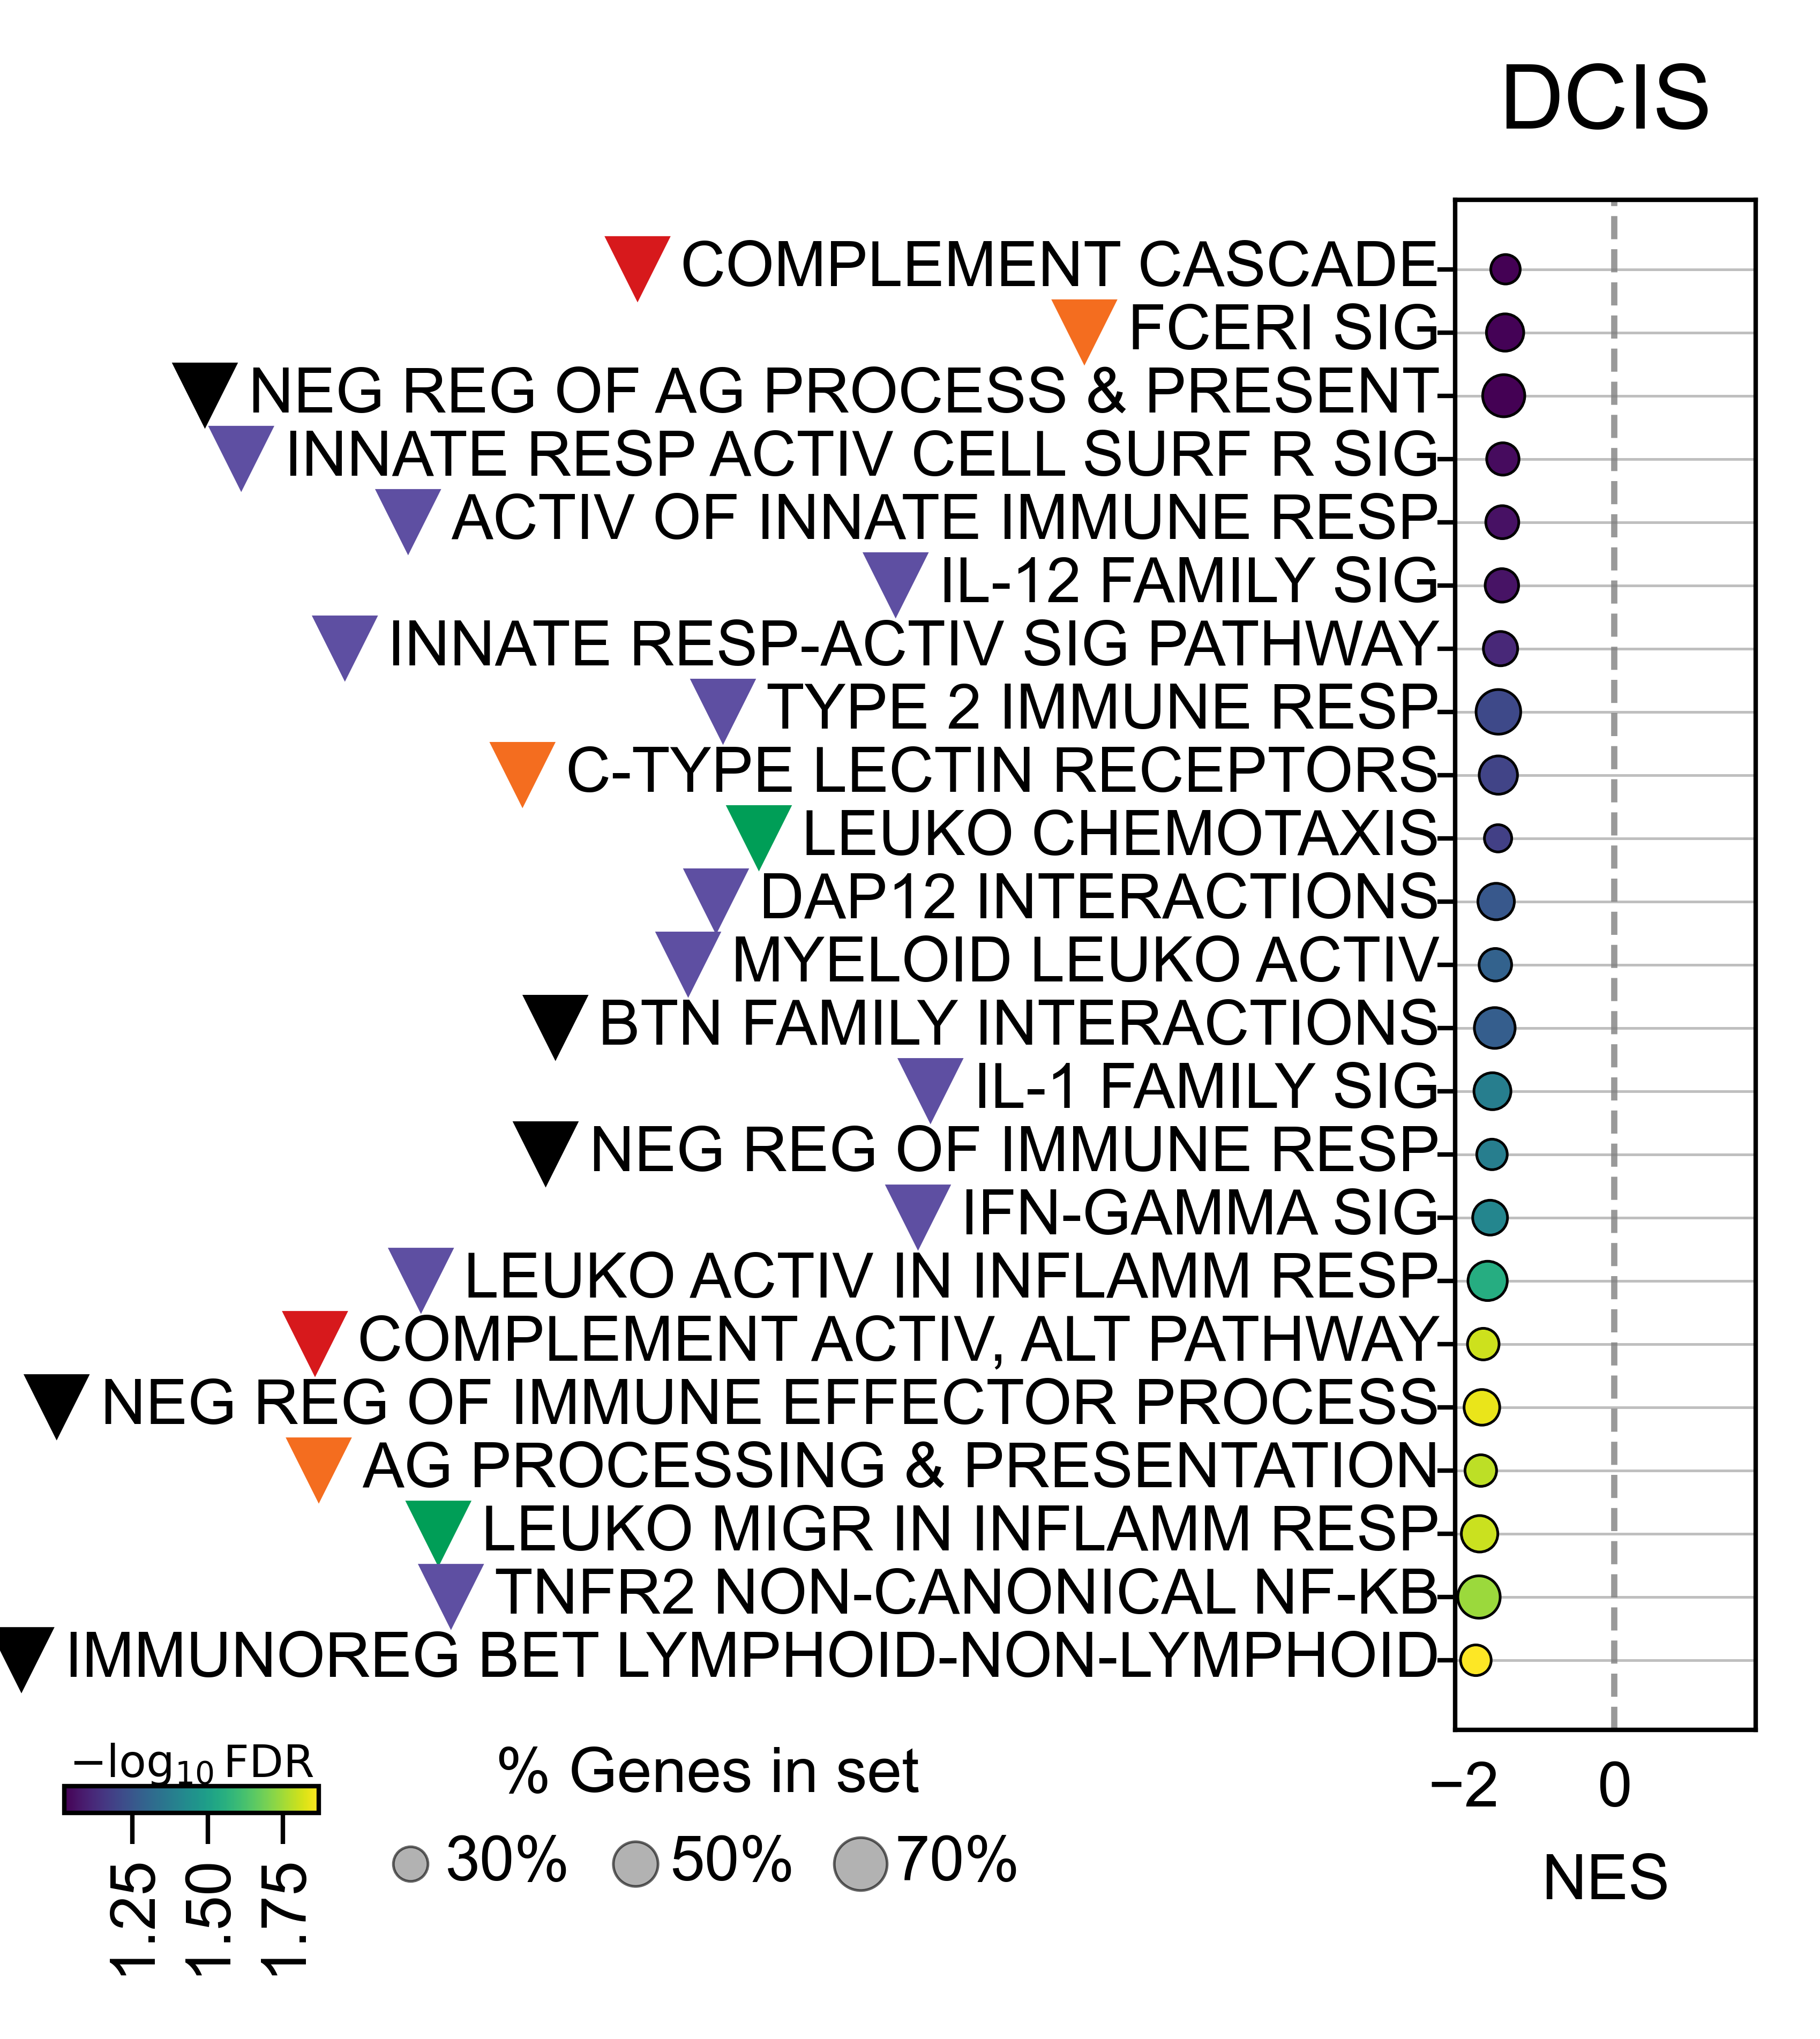

In [138]:
import pandas as pd
import matplotlib.pyplot as plt
from textwrap import fill
from matplotlib import font_manager as fm

title_map = {"HRL": "High-Risk Lesion", "DCIS": "DCIS", "BC": "Breast Cancer"}

# -----------------------------
# Prepare data
# -----------------------------
dfp2 = dfp[dfp["Term"].isin(paths_relevant)].copy()
dfp2["Term"] = pd.Categorical(dfp2["Term"], categories=paths_relevant, ordered=True)
dfp2 = dfp2.sort_values("Term").reset_index(drop=True)

dfp2["Term_full"] = dfp2["Term"].astype(str)
dfp2["Term_short"] = dfp2["Term_full"].map(short_name_map).fillna(dfp2["Term_full"])
dfp2["Term_plot"] = dfp2["Term_short"].apply(lambda x: fill(str(x), width=38))

# -----------------------------
# Parameters
# -----------------------------
dot_scale = 0.5
cmap = plt.cm.viridis
arial_font = fm.FontProperties(family="Arial")

label_fontsize = 7
label_right_x = -0.05

triangle_gap_px = 30
triangle_size = 55
triangle_half_width_px = 10

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(1.8, 3.5))

# Main control:
# larger left = wider ylabel region + narrower bubble box
fig.subplots_adjust(left=0.72, right=0.98, bottom=0.24, top=0.92)

ypos = list(range(len(dfp2)))

sc = ax.scatter(
    dfp2["NES"],
    ypos,
    s=dfp2["Tag %"] * dot_scale,
    c=dfp2["log_p"],
    cmap=cmap,
    edgecolor="black",
    linewidth=0.3,
    zorder=3
)

# -----------------------------
# Manual y labels
# -----------------------------
ax.set_yticks(ypos)
ax.set_yticklabels([])
ax.invert_yaxis()

label_text_objects = []

for i, row in dfp2.iterrows():
    txt = ax.text(
        label_right_x,
        i,
        row["Term_plot"],
        transform=ax.get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=label_fontsize,
        clip_on=False
    )
    label_text_objects.append((txt, row["Term_full"], i))

# -----------------------------
# Axes formatting
# -----------------------------
nes_max = dfp2["NES"].abs().max()
nes_min = dfp2["NES"].min()
ax.set_xlim([nes_min * 1.15, nes_max * 1.02])

ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis="x", labelsize=7)
ax.tick_params(axis="y", length=2, labelsize=6, pad=1)
ax.set_title(title_map.get(DzState, DzState), fontsize=10, pad=8)

ax.grid(axis="y", linestyle="-", linewidth=0.3, color="gray", alpha=0.5, zorder=0)
ax.axvline(x=0, linestyle="--", linewidth=0.7, color="gray", alpha=0.8, zorder=1)

# -----------------------------
# Draw once, then measure manual labels
# -----------------------------
fig.canvas.draw()
renderer = fig.canvas.get_renderer()

label_bboxes = [
    txt.get_window_extent(renderer=renderer)
    for txt, term_full, i in label_text_objects
]

leftmost_label_x_display = min(b.x0 for b in label_bboxes)
lowest_label_y_display = min(b.y0 for b in label_bboxes)

leftmost_label_x_fig, lowest_label_y_fig = fig.transFigure.inverted().transform(
    (leftmost_label_x_display, lowest_label_y_display)
)

# -----------------------------
# Triangles immediately left of labels
# -----------------------------
for txt, term_full, i in label_text_objects:
    tri = triangle_map.get(term_full)
    if tri is None:
        continue

    bbox = txt.get_window_extent(renderer=renderer)
    triangle_x_display = bbox.x0 - triangle_gap_px - triangle_half_width_px
    triangle_x_axes = ax.transAxes.inverted().transform((triangle_x_display, bbox.y0))[0]

    ax.scatter(
        triangle_x_axes,
        i,
        marker=tri["marker"],
        s=triangle_size,
        color=tri["color"],
        edgecolor="none",
        transform=ax.get_yaxis_transform(),
        clip_on=False,
        zorder=5
    )

# -----------------------------
# Colorbar: left aligned to leftmost ylabel
# -----------------------------
cbar_left = leftmost_label_x_fig
cbar_bottom = lowest_label_y_fig - 0.055
cbar_width = 0.22
cbar_height = 0.012

cax = fig.add_axes([cbar_left, cbar_bottom, cbar_width, cbar_height])

cbar = fig.colorbar(sc, cax=cax, orientation="horizontal")
cbar.set_label(
    r"$-\log_{10}\mathrm{FDR}$",
    fontproperties=arial_font,
    fontsize=5,
    labelpad=1
)
cbar.ax.xaxis.set_label_position("top")
cbar.ax.xaxis.set_ticks_position("bottom")
cbar.ax.tick_params(labelsize=7, pad=1, rotation=90)
cbar.solids.set_rasterized(True)

# -----------------------------
# Bubble legend: right of colorbar
# -----------------------------
size_handles = [
    plt.scatter(
        [], [],
        s=size * dot_scale,
        c="gray",
        alpha=0.6,
        edgecolor="black",
        linewidth=0.3
    )
    for size in [30, 50, 70]
]

bubble_legend_x = cbar_left + cbar_width * 1.2
bubble_legend_y = cbar_bottom - 0.003

leg = fig.legend(
    size_handles,
    ["30%", "50%", "70%"],
    title="% Genes in set",
    title_fontsize=7,
    fontsize=7,
    frameon=False,
    loc="center left",
    bbox_to_anchor=(bubble_legend_x, bubble_legend_y),
    ncol=3,
    columnspacing=0.8,
    handletextpad=0.3,
    borderaxespad=0
)

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    f"plots/F5/Bubble_DC_{DzState}.png",
    bbox_inches="tight",
    pad_inches=0.2, 
    dpi=600
)

plt.show()

### BC

In [17]:
DzState, db = 'BC', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['INTERFERON ALPHA/BETA SIGNALING',
       'COSTIMULATION BY THE CD28 FAMILY',
       'INTERLEUKIN-20 FAMILY SIGNALING',
       'ROS AND RNS PRODUCTION IN PHAGOCYTES',
       'COMPLEMENT ACTIVATION, LECTIN PATHWAY', 'CELLULAR EXTRAVASATION'],
      dtype=object)

In [18]:
paths_relevant = [
    'INTERFERON ALPHA/BETA SIGNALING',
       'COSTIMULATION BY THE CD28 FAMILY',
       'INTERLEUKIN-20 FAMILY SIGNALING',
       'ROS AND RNS PRODUCTION IN PHAGOCYTES',
       'COMPLEMENT ACTIVATION, LECTIN PATHWAY',
    'CELLULAR EXTRAVASATION'
]

In [19]:
dfp_sel = dfp[dfp['Term'].isin(paths_relevant)]
dfp_sel.to_csv(f'data/Tables/DC_{DzState}.csv')

In [12]:
short_name_map = {
    'INTERFERON ALPHA/BETA SIGNALING':
        'IFN-ALPHA/BETA SIG',

    'COSTIMULATION BY THE CD28 FAMILY':
        'CD28 FAMILY COSTIM',

    'INTERLEUKIN-20 FAMILY SIGNALING':
        'IL-20 FAMILY SIG',

    'ROS AND RNS PRODUCTION IN PHAGOCYTES':
        'ROS/RNS PROD IN PHAGOCYTES',

    'COMPLEMENT ACTIVATION, LECTIN PATHWAY':
        'COMPLEMENT ACTIV, LECTIN',

    'CELLULAR EXTRAVASATION':
        'CELLULAR EXTRAVASATION'
}

In [13]:
triangle_map = {
    'INTERFERON ALPHA/BETA SIGNALING':
        {"marker": "^", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'COSTIMULATION BY THE CD28 FAMILY':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation / T-cell costimulation related

    'INTERLEUKIN-20 FAMILY SIGNALING':
        {"marker": "v", "color": "#009E57"},  # green; Migration / chemotaxis / tissue inflammatory response

    'ROS AND RNS PRODUCTION IN PHAGOCYTES':
        {"marker": "v", "color": "#2CA9E1"},  # blue; Phagocytosis

    'COMPLEMENT ACTIVATION, LECTIN PATHWAY':
        {"marker": "v", "color": "#D7191C"},  # red; Complement

    'CELLULAR EXTRAVASATION':
        {"marker": "v", "color": "#009E57"}   # green; Migration / chemotaxis
}

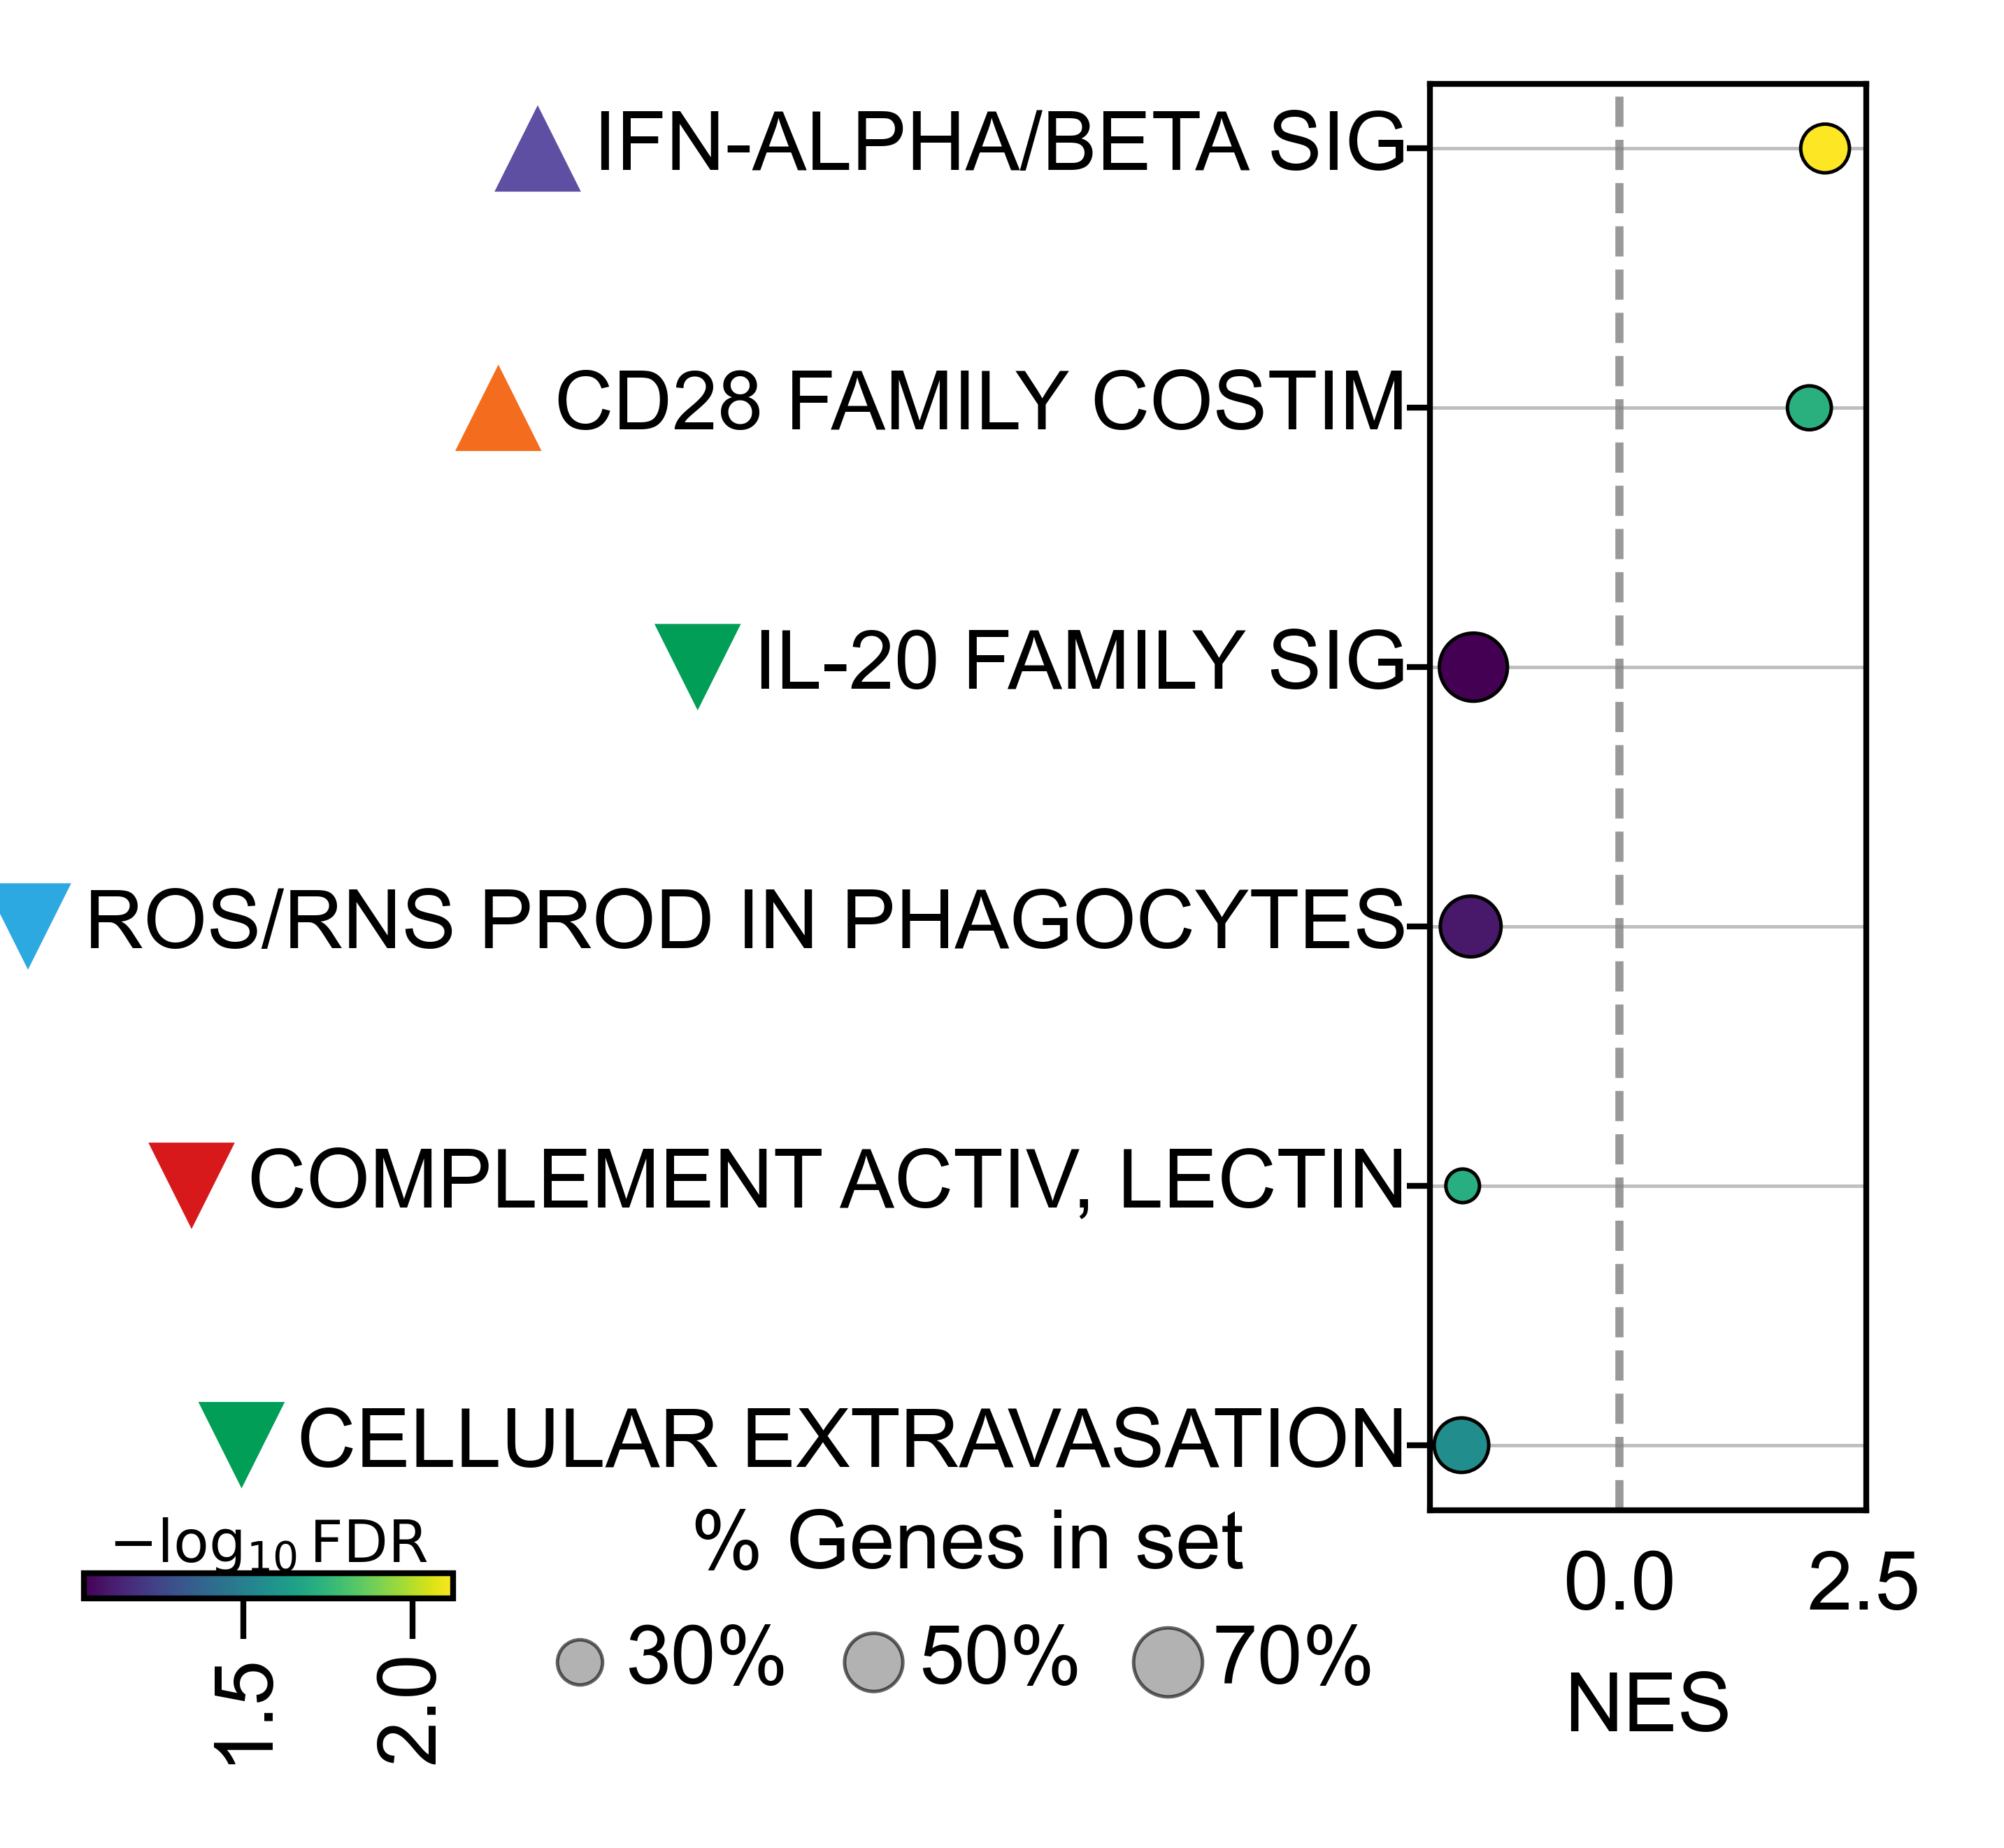

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from textwrap import fill
from matplotlib import font_manager as fm

title_map = {"HRL": "High-Risk Lesion", "DCIS": "DCIS", "BC": "Breast Cancer"}

# -----------------------------
# Prepare data
# -----------------------------
dfp2 = dfp[dfp["Term"].isin(paths_relevant)].copy()
dfp2["Term"] = pd.Categorical(dfp2["Term"], categories=paths_relevant, ordered=True)
dfp2 = dfp2.sort_values("Term").reset_index(drop=True)

dfp2["Term_full"] = dfp2["Term"].astype(str)
dfp2["Term_short"] = dfp2["Term_full"].map(short_name_map).fillna(dfp2["Term_full"])
dfp2["Term_plot"] = dfp2["Term_short"].apply(lambda x: fill(str(x), width=38))

# -----------------------------
# Parameters
# -----------------------------
dot_scale = 0.5
cmap = plt.cm.viridis
arial_font = fm.FontProperties(family="Arial")

label_fontsize = 7
label_right_x = -0.05

triangle_gap_px = 30
triangle_size = 55
triangle_half_width_px = 10

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(2, 2.5))

# Main control:
# larger left = wider ylabel region + narrower bubble box
fig.subplots_adjust(left=0.72, right=0.98, bottom=0.24, top=0.92)

ypos = list(range(len(dfp2)))

sc = ax.scatter(
    dfp2["NES"],
    ypos,
    s=dfp2["Tag %"] * dot_scale,
    c=dfp2["log_p"],
    cmap=cmap,
    edgecolor="black",
    linewidth=0.3,
    zorder=3
)

# -----------------------------
# Manual y labels
# -----------------------------
ax.set_yticks(ypos)
ax.set_yticklabels([])
ax.invert_yaxis()

label_text_objects = []

for i, row in dfp2.iterrows():
    txt = ax.text(
        label_right_x,
        i,
        row["Term_plot"],
        transform=ax.get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=label_fontsize,
        clip_on=False
    )
    label_text_objects.append((txt, row["Term_full"], i))

# -----------------------------
# Axes formatting
# -----------------------------
nes_max = dfp2["NES"].abs().max()
nes_min = dfp2["NES"].min()
ax.set_xlim([nes_min * 1.2, nes_max * 1.2])

ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis="x", labelsize=7)
ax.tick_params(axis="y", length=2, labelsize=6, pad=1)
ax.set_title('')#(title_map.get(DzState, DzState), fontsize=10, pad=8)

ax.grid(axis="y", linestyle="-", linewidth=0.3, color="gray", alpha=0.5, zorder=0)
ax.axvline(x=0, linestyle="--", linewidth=0.7, color="gray", alpha=0.8, zorder=1)

# -----------------------------
# Draw once, then measure manual labels
# -----------------------------
fig.canvas.draw()
renderer = fig.canvas.get_renderer()

label_bboxes = [
    txt.get_window_extent(renderer=renderer)
    for txt, term_full, i in label_text_objects
]

leftmost_label_x_display = min(b.x0 for b in label_bboxes)
lowest_label_y_display = min(b.y0 for b in label_bboxes)

leftmost_label_x_fig, lowest_label_y_fig = fig.transFigure.inverted().transform(
    (leftmost_label_x_display, lowest_label_y_display)
)

# -----------------------------
# Triangles immediately left of labels
# -----------------------------
for txt, term_full, i in label_text_objects:
    tri = triangle_map.get(term_full)
    if tri is None:
        continue

    bbox = txt.get_window_extent(renderer=renderer)
    triangle_x_display = bbox.x0 - triangle_gap_px - triangle_half_width_px
    triangle_x_axes = ax.transAxes.inverted().transform((triangle_x_display, bbox.y0))[0]

    ax.scatter(
        triangle_x_axes,
        i,
        marker=tri["marker"],
        s=triangle_size,
        color=tri["color"],
        edgecolor="none",
        transform=ax.get_yaxis_transform(),
        clip_on=False,
        zorder=5
    )

# -----------------------------
# Colorbar: left aligned to leftmost ylabel
# -----------------------------
cbar_left = leftmost_label_x_fig
cbar_bottom = lowest_label_y_fig - 0.055
cbar_width = 0.22
cbar_height = 0.012

cax = fig.add_axes([cbar_left, cbar_bottom, cbar_width, cbar_height])

cbar = fig.colorbar(sc, cax=cax, orientation="horizontal")
cbar.set_label(
    r"$-\log_{10}\mathrm{FDR}$",
    fontproperties=arial_font,
    fontsize=5,
    labelpad=1
)
cbar.ax.xaxis.set_label_position("top")
cbar.ax.xaxis.set_ticks_position("bottom")
cbar.ax.tick_params(labelsize=7, pad=1, rotation=90)
cbar.solids.set_rasterized(True)

# -----------------------------
# Bubble legend: right of colorbar
# -----------------------------
size_handles = [
    plt.scatter(
        [], [],
        s=size * dot_scale,
        c="gray",
        alpha=0.6,
        edgecolor="black",
        linewidth=0.3
    )
    for size in [30, 50, 70]
]

bubble_legend_x = cbar_left + cbar_width * 1.2
bubble_legend_y = cbar_bottom - 0.003

leg = fig.legend(
    size_handles,
    ["30%", "50%", "70%"],
    title="% Genes in set",
    title_fontsize=7,
    fontsize=7,
    frameon=False,
    loc="center left",
    bbox_to_anchor=(bubble_legend_x, bubble_legend_y),
    ncol=3,
    columnspacing=0.8,
    handletextpad=0.3,
    borderaxespad=0
)

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    f"plots/F5/Bubble_DC_{DzState}.png",
    bbox_inches="tight",
    pad_inches=0.2, 
    dpi=600
)

plt.show()